In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import time
import helper_functions as hf

In [2]:
global_start_time = time.time()
try:
	customer_data = pd.read_csv('./data/Lending Club Loan Data/X.csv')
	target = pd.read_csv('./data/Lending Club Loan Data/target.csv')
	customer_data['target'] = target['y']
	pd.options.display.max_columns = None
	pd.options.display.max_rows = None
except Exception as e:
	print(f"An error occurred while loading the data: {e}")

In [3]:
customer_data.head(10)

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,target
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,NY,18.24,0,1,NaN,9,1,4341,10.3,34,w,2386.02,167.02,113.98,53.04,0.0,2.0,1.0,2.0,2.0,2.0,7.0,2137.0,28.0,1.0,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001,0
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,LA,26.52,0,0,71.0,13,1,12315,24.2,44,w,29387.75,1507.11,612.25,894.86,0.0,4.0,2.0,3.0,3.0,4.0,5.0,998.0,57.0,2.0,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987,0
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,MI,10.51,0,0,NaN,8,0,4599,19.1,13,w,4787.21,353.89,212.79,141.10,0.0,0.0,0.0,2.0,14.0,0.0,2.0,0.0,35.0,1.0,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011,0
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,WA,16.74,0,0,NaN,10,0,5468,78.1,13,w,3831.93,286.71,168.07,118.64,0.0,1.0,3.0,5.0,5.0,0.0,0.0,3761.0,70.0,2.0,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006,0
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,MD,26.35,0,0,NaN,12,0,829,3.6,26,w,29339.02,1423.21,660.98,762.23,0.0,3.0,3.0,5.0,4.0,2.0,4.0,516.0,54.0,1.0,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000,0
5,5550,15.02,192.45,C3,Director COE,10+ years,MORTGAGE,152500.0,Not Verified,credit_card,IN,37.94,0,3,NaN,18,0,53854,48.1,44,w,5302.50,377.95,247.50,130.45,0.0,1.0,2.0,3.0,4.0,1.0,4.0,17584.0,58.0,2.0,6,NaN,NaN,Cash,36,Dec,2018,4,Sep,2002,0
6,2000,17.97,72.28,D1,Account Manager,4 years,RENT,51000.0,Source Verified,debt_consolidation,IL,2.40,0,1,NaN,1,0,0,0.0,9,w,1914.71,141.56,85.29,56.27,0.0,0.0,2.0,3.0,7.0,0.0,1.0,0.0,100.0,0.0,1,NaN,NaN,Cash,36,Dec,2018,6,Nov,2004,0
7,6000,13.56,203.79,C1,Assistant Director,10+ years,RENT,65000.0,Source Verified,credit_card,IN,30.10,0,0,NaN,19,0,38476,69.3,37,w,5864.01,201.53,135.99,65.54,0.0,0.0,0.0,1.0,23.0,0.0,2.0,9413.0,74.0,1.0,0,NaN,NaN,DirectPay,36,Dec,2018,4,Nov,1997,0
8,5000,17.97,180.69,D1,Legal Assistant III,10+ years,MORTGAGE,53580.0,Source Verified,debt_consolidation,FL,21.16,0,1,32.0,8,0,8018,35.2,38,w,4786.79,353.89,213.21,140.68,0.0,5.0,5.0,5.0,3.0,1.0,6.0,3132.0,73.0,2.0,4,33.0,32.0,Cash,36,Dec,2018,3,Aug,1998,0
9,6000,14.47,206.44,C2,NaN,< 1 year,OWN,300000.0,Not Verified,debt_consolidation,CT,17.43,1,1,17.0,38,0,65950,49.8,58,w,5730.20,405.64,269.80,135.84,0.0,1.0,1.0,3.0,7.0,1.0,12.0,15926.0,48.0,2.0,2,NaN,17.0,Cash,36,Dec,2018,0,Apr,2002,0


### We have 2 139 643 records and 46 columns

In [4]:
customer_data.shape

(2139643, 46)

Data is inbalanced, around 13 % of data refer to the default case (1), other refer to non-default case (0)

In [5]:
from sklearn.model_selection import train_test_split

# Reducing the dataset to 2% of its original size while maintaining the class distribution
random_state = 68
customer_data, _ = train_test_split(
	customer_data,
	train_size=0.02,
	stratify=customer_data['target'],
	random_state=random_state
)
customer_data['target'].value_counts()

target
0    37198
1     5594
Name: count, dtype: int64

### Dropping columns with many NaN values

In [6]:
customer_data.isna().sum()

funded_amnt                               0
interest_rate                             0
monthly_payment                           0
grade                                     0
emp_title                              2843
emp_length                             2515
home_ownership_status                     0
annual_income                             0
verification_status                       0
loan_purpose                              0
addr_state                                0
dept_paym_income_ratio                    0
num_30+_delinq_in_2yrs                    0
num_inq_in_6mths                          0
mths_since_last_delinq                21619
num_open_credit_lines                     0
num_derogatory_pub_rec                    0
total_credit_revolving_bal                0
used_credit_share                         0
tot_num_credit_lines                      0
initial_list_status                       0
remaining_princ_for_tot_amnt_fund         0
paym_rec_for_tot_amnt_fund      

In [7]:
major_nans_in_columns = (
    customer_data
    .isna()
    .sum() > 0.3 * len(customer_data)
)
customer_data = customer_data.loc[:, ~major_nans_in_columns]

In [8]:
customer_data = (
	customer_data
	.dropna()
	.reset_index(drop=True)
)
customer_data.shape

(39935, 34)

In [9]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,target
0,5000,16.99,178.24,D1,Secretary I,< 1 year,RENT,40000.0,Source Verified,other,MD,15.75,1,0,8,0,4437,65.3,22,w,2395.13,3765.420000,2604.87,1160.55,0.0,1,Cash,36,May,2017,2,Sep,2000,0
1,1500,18.25,54.42,D3,Payroll Administrator,10+ years,RENT,63749.0,Verified,vacation,MD,7.32,0,0,4,1,746,74.6,8,w,0.00,1955.932732,1500.00,455.93,0.0,0,Cash,36,Feb,2016,2,Jun,1991,0
2,33425,20.49,1250.56,E1,Saint Anthony Hospital,10+ years,RENT,75000.0,Verified,debt_consolidation,IL,31.58,0,2,16,0,38198,58.6,51,f,0.00,40285.089985,33425.00,6860.09,0.0,2,Cash,36,Nov,2012,6,Oct,1994,0
3,15000,17.09,373.52,D1,Estimator,3 years,RENT,95000.0,Source Verified,debt_consolidation,NY,12.62,0,0,7,0,8841,65.5,10,w,11332.27,7490.220000,3667.73,3822.49,0.0,3,Cash,60,Jun,2017,1,Jul,2011,0
4,20000,18.25,725.56,E1,Foreman,10+ years,MORTGAGE,70000.0,Verified,small_business,NC,26.97,0,2,15,0,21524,47.8,28,w,0.00,25468.895172,20000.00,5468.90,0.0,2,Cash,36,Apr,2015,2,Mar,1996,0


In [10]:
(customer_data['funded_amnt'].value_counts().index.min(),
customer_data['funded_amnt'].value_counts().index.max())

(900, 40000)

In [11]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39935 entries, 0 to 39934
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   funded_amnt                        39935 non-null  int64  
 1   interest_rate                      39935 non-null  float64
 2   monthly_payment                    39935 non-null  float64
 3   grade                              39935 non-null  object 
 4   emp_title                          39935 non-null  object 
 5   emp_length                         39935 non-null  object 
 6   home_ownership_status              39935 non-null  object 
 7   annual_income                      39935 non-null  float64
 8   verification_status                39935 non-null  object 
 9   loan_purpose                       39935 non-null  object 
 10  addr_state                         39935 non-null  object 
 11  dept_paym_income_ratio             39935 non-null  flo

In [12]:
numerical_data, numerical_data_describe = hf.numeric_describe(customer_data)
numerical_data_describe

,funded_amnt,interest_rate,monthly_payment,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,loan_term_months,issue_date_year,region_code,earliest_cr_line_year,target
count,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00
mean,14885.63,13.06,441.19,80631.03,18.01,0.32,0.60,11.72,0.20,16857.00,50.90,24.44,3913.30,12224.01,9648.21,2436.51,1.49,1.51,42.89,2015.73,4.62,1999.62,0.13
std,8986.87,4.78,260.98,84599.07,8.35,0.89,0.91,5.65,0.61,21978.81,24.50,12.11,7021.92,9914.58,8310.63,2691.70,11.69,2.04,10.86,1.79,3.10,7.55,0.34
min,900.00,5.31,25.81,5000.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,36.00,2007.00,0.00,1956.00,0.00
25%,8000.00,9.49,253.23,49000.00,11.74,0.00,0.00,8.00,0.00,6083.00,32.30,16.00,0.00,4634.82,3070.78,721.84,0.00,0.00,36.00,2015.00,2.00,1996.00,0.00
50%,12750.00,12.62,376.57,68000.00,17.54,0.00,0.00,11.00,0.00,11483.00,50.90,23.00,0.00,9631.27,7234.34,1522.34,0.00,1.00,36.00,2016.00,4.00,2001.00,0.00
75%,20000.00,15.80,581.55,96000.00,23.90,0.00,1.00,15.00,0.00,20364.50,69.70,31.00,5548.97,17210.07,14039.30,3107.11,0.00,2.00,60.00,2017.00,8.00,2005.00,0.00
max,40000.00,30.99,1587.23,8365188.00,49.15,26.00,16.00,70.00,49.00,765289.00,134.10,133.00,39078.12,62082.45,40000.00,27082.45,748.56,26.00,60.00,2018.00,9.00,2015.00,1.00
unique,1269.00,505.00,16443.00,3871.00,3899.00,20.00,12.00,58.00,14.00,23688.00,1059.00,103.00,13755.00,38826.00,19382.00,37048.00,1019.00,27.00,2.00,12.00,10.00,57.00,2.00
var_coeff [%],60.37,36.58,59.15,104.92,46.37,277.67,153.04,48.26,304.35,130.38,48.14,49.55,179.44,81.11,86.14,110.47,783.16,135.60,25.32,0.09,67.14,0.38,259.61


In [13]:
# Inserting new feature - credit_history_age columns based on the appropriate date columns
credit_history_col_index = (
    customer_data
    .columns
    .to_list()
    .index('issue_date_year') + 1
)
customer_data.insert(
    credit_history_col_index,
    'credit_history_age',
	customer_data['issue_date_year'] - customer_data['earliest_cr_line_year']
)
customer_data = customer_data.drop(
	columns=['issue_date_month', 'issue_date_year', 'earliest_cr_line_month', 'earliest_cr_line_year']
)

In [14]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,disbursement_method,loan_term_months,credit_history_age,region_code,target
0,5000,16.99,178.24,D1,Secretary I,< 1 year,RENT,40000.00,Source Verified,other,MD,15.75,1,0,8,0,4437,65.30,22,w,2395.13,3765.42,2604.87,1160.55,0.00,1,Cash,36,17,2,0
1,1500,18.25,54.42,D3,Payroll Administrator,10+ years,RENT,63749.00,Verified,vacation,MD,7.32,0,0,4,1,746,74.60,8,w,0.00,1955.93,1500.00,455.93,0.00,0,Cash,36,25,2,0
2,33425,20.49,1250.56,E1,Saint Anthony Hospital,10+ years,RENT,75000.00,Verified,debt_consolidation,IL,31.58,0,2,16,0,38198,58.60,51,f,0.00,40285.09,33425.00,6860.09,0.00,2,Cash,36,18,6,0
3,15000,17.09,373.52,D1,Estimator,3 years,RENT,95000.00,Source Verified,debt_consolidation,NY,12.62,0,0,7,0,8841,65.50,10,w,11332.27,7490.22,3667.73,3822.49,0.00,3,Cash,60,6,1,0
4,20000,18.25,725.56,E1,Foreman,10+ years,MORTGAGE,70000.00,Verified,small_business,NC,26.97,0,2,15,0,21524,47.80,28,w,0.00,25468.90,20000.00,5468.90,0.00,2,Cash,36,19,2,0


In [15]:
numerical_data, numerical_data_describe = hf.numeric_describe(customer_data)
numerical_data_describe

,funded_amnt,interest_rate,monthly_payment,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,loan_term_months,credit_history_age,region_code,target
count,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00
mean,14885.63,13.06,441.19,80631.03,18.01,0.32,0.60,11.72,0.20,16857.00,50.90,24.44,3913.30,12224.01,9648.21,2436.51,1.49,1.51,42.89,16.11,4.62,0.13
std,8986.87,4.78,260.98,84599.07,8.35,0.89,0.91,5.65,0.61,21978.81,24.50,12.11,7021.92,9914.58,8310.63,2691.70,11.69,2.04,10.86,7.37,3.10,0.34
min,900.00,5.31,25.81,5000.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,36.00,0.00,0.00,0.00
25%,8000.00,9.49,253.23,49000.00,11.74,0.00,0.00,8.00,0.00,6083.00,32.30,16.00,0.00,4634.82,3070.78,721.84,0.00,0.00,36.00,11.00,2.00,0.00
50%,12750.00,12.62,376.57,68000.00,17.54,0.00,0.00,11.00,0.00,11483.00,50.90,23.00,0.00,9631.27,7234.34,1522.34,0.00,1.00,36.00,15.00,4.00,0.00
75%,20000.00,15.80,581.55,96000.00,23.90,0.00,1.00,15.00,0.00,20364.50,69.70,31.00,5548.97,17210.07,14039.30,3107.11,0.00,2.00,60.00,20.00,8.00,0.00
max,40000.00,30.99,1587.23,8365188.00,49.15,26.00,16.00,70.00,49.00,765289.00,134.10,133.00,39078.12,62082.45,40000.00,27082.45,748.56,26.00,60.00,58.00,9.00,1.00
unique,1269.00,505.00,16443.00,3871.00,3899.00,20.00,12.00,58.00,14.00,23688.00,1059.00,103.00,13755.00,38826.00,19382.00,37048.00,1019.00,27.00,2.00,56.00,10.00,2.00
var_coeff [%],60.37,36.58,59.15,104.92,46.37,277.67,153.04,48.26,304.35,130.38,48.14,49.55,179.44,81.11,86.14,110.47,783.16,135.60,25.32,45.75,67.14,259.61


In [16]:
categorical_data = (
    customer_data
    .select_dtypes(["object"])
    .dropna()
    .reset_index(drop=True)
)
categorical_data.describe()

,grade,emp_title,emp_length,home_ownership_status,verification_status,loan_purpose,addr_state,initial_list_status,disbursement_method
count,39935,39935,39935,39935,39935,39935,39935,39935,39935
unique,35,20438,11,4,3,14,50,2,2
top,C1,Teacher,10+ years,MORTGAGE,Source Verified,debt_consolidation,CA,w,Cash
freq,2601,715,14378,19454,16466,22588,5581,26738,38644


In [17]:
(numerical_data.columns.size, categorical_data.columns.size)

(22, 9)

### Data Visualization

Drawing distribution plots [31/31]

('funded_amnt', 'histogram')
('interest_rate', 'histogram')
('monthly_payment', 'histogram')
('grade', 'barplot')
('emp_title', 'barplot')
('emp_length', 'barplot')
('home_ownership_status', 'barplot')
('annual_income', 'histogram')
('verification_status', 'barplot')
('loan_purpose', 'barplot')
('addr_state', 'barplot')
('dept_paym_income_ratio', 'histogram')
('num_30+_delinq_in_2yrs', 'barplot')
('num_inq_in_6mths', 'barplot')
('num_open_credit_lines', 'histogram')
('num_derogatory_pub_rec', 'barplot')
('total_credit_revolving_bal', 'histogram')
('used_credit_share', 'histogram')
('tot_num_credit_lines', 'histogram')
('initial_list_status', 'barplot')
('remaining_princ_for_tot_amnt_fund', 'histogram')
('paym_rec_for_tot_amnt_fund', 'histogram')
('princ_rec', 'histogram')
('interest_rec', 'histogram')
('late_fees_rec', 'histogram')
('num_inq_in_12mths', 'histogram')
('disbursement_method', 'barplot')
('loan_term_months', 'barplot')
('credit_history_a

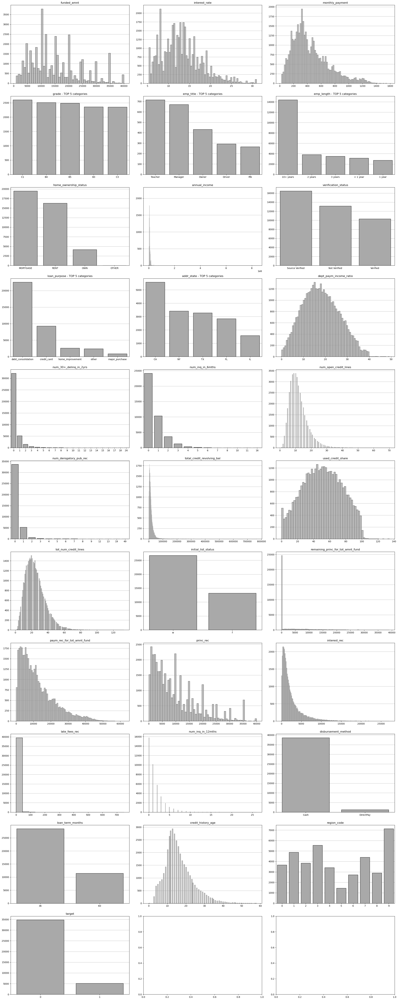

In [18]:
hf.draw_distribution(
    df=customer_data,
    subplot_size=(24, 60),
    subplot_cols=3,
	plot_color='darkgrey' 
)

 "loan_term_months" column has only 2 values so we can treat it as category variable as well as for the "region_code" variable

In [19]:
customer_data['loan_term_months'] = customer_data['loan_term_months'].astype('object')
customer_data['region_code'] = customer_data['region_code'].astype('object')
categorical_data = customer_data.select_dtypes(['object'])
categorical_data.head()

,grade,emp_title,emp_length,home_ownership_status,verification_status,loan_purpose,addr_state,initial_list_status,disbursement_method,loan_term_months,region_code
0,D1,Secretary I,< 1 year,RENT,Source Verified,other,MD,w,Cash,36,2
1,D3,Payroll Administrator,10+ years,RENT,Verified,vacation,MD,w,Cash,36,2
2,E1,Saint Anthony Hospital,10+ years,RENT,Verified,debt_consolidation,IL,f,Cash,36,6
3,D1,Estimator,3 years,RENT,Source Verified,debt_consolidation,NY,w,Cash,60,1
4,E1,Foreman,10+ years,MORTGAGE,Verified,small_business,NC,w,Cash,36,2


Categorical and numerical statistics (after adjusting variables to the proper groups of data)

In [20]:
categorical_data.describe()

,grade,emp_title,emp_length,home_ownership_status,verification_status,loan_purpose,addr_state,initial_list_status,disbursement_method,loan_term_months,region_code
count,39935,39935,39935,39935,39935,39935,39935,39935,39935,39935,39935
unique,35,20438,11,4,3,14,50,2,2,2,10
top,C1,Teacher,10+ years,MORTGAGE,Source Verified,debt_consolidation,CA,w,Cash,36,9
freq,2601,715,14378,19454,16466,22588,5581,26738,38644,28470,7124


In [21]:
numerical_data, numerical_data_describe = hf.numeric_describe(customer_data)
numerical_data_describe

,funded_amnt,interest_rate,monthly_payment,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,credit_history_age,target
count,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00,39935.00
mean,14885.63,13.06,441.19,80631.03,18.01,0.32,0.60,11.72,0.20,16857.00,50.90,24.44,3913.30,12224.01,9648.21,2436.51,1.49,1.51,16.11,0.13
std,8986.87,4.78,260.98,84599.07,8.35,0.89,0.91,5.65,0.61,21978.81,24.50,12.11,7021.92,9914.58,8310.63,2691.70,11.69,2.04,7.37,0.34
min,900.00,5.31,25.81,5000.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,8000.00,9.49,253.23,49000.00,11.74,0.00,0.00,8.00,0.00,6083.00,32.30,16.00,0.00,4634.82,3070.78,721.84,0.00,0.00,11.00,0.00
50%,12750.00,12.62,376.57,68000.00,17.54,0.00,0.00,11.00,0.00,11483.00,50.90,23.00,0.00,9631.27,7234.34,1522.34,0.00,1.00,15.00,0.00
75%,20000.00,15.80,581.55,96000.00,23.90,0.00,1.00,15.00,0.00,20364.50,69.70,31.00,5548.97,17210.07,14039.30,3107.11,0.00,2.00,20.00,0.00
max,40000.00,30.99,1587.23,8365188.00,49.15,26.00,16.00,70.00,49.00,765289.00,134.10,133.00,39078.12,62082.45,40000.00,27082.45,748.56,26.00,58.00,1.00
unique,1269.00,505.00,16443.00,3871.00,3899.00,20.00,12.00,58.00,14.00,23688.00,1059.00,103.00,13755.00,38826.00,19382.00,37048.00,1019.00,27.00,56.00,2.00
var_coeff [%],60.37,36.58,59.15,104.92,46.37,277.67,153.04,48.26,304.35,130.38,48.14,49.55,179.44,81.11,86.14,110.47,783.16,135.60,45.75,259.61


Drawing boxplots [19/19]
[469, 800, 1309, 1916, 24, 7758, 1819, 987, 6297, 2452, 3, 901, 4022, 1345, 1090, 2987, 1524, 1962, 1091]


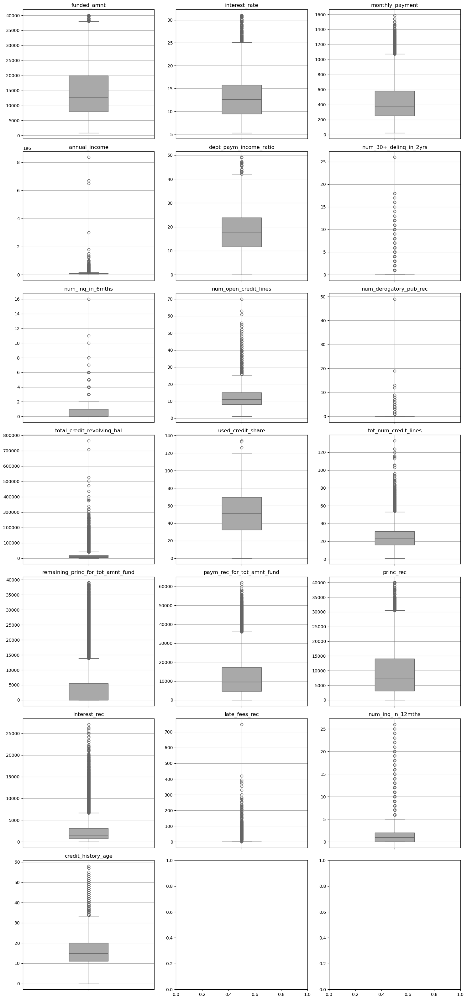

In [22]:
hf.draw_boxplots(
    df=numerical_data.drop(columns='target'),
    subplot_size=(15, 32),
    plot_color='darkgrey'
)

In [23]:
categorical_data.describe()

,grade,emp_title,emp_length,home_ownership_status,verification_status,loan_purpose,addr_state,initial_list_status,disbursement_method,loan_term_months,region_code
count,39935,39935,39935,39935,39935,39935,39935,39935,39935,39935,39935
unique,35,20438,11,4,3,14,50,2,2,2,10
top,C1,Teacher,10+ years,MORTGAGE,Source Verified,debt_consolidation,CA,w,Cash,36,9
freq,2601,715,14378,19454,16466,22588,5581,26738,38644,28470,7124


In [24]:
customer_data = customer_data.drop(
    columns=['grade', 'emp_title', 'addr_state']
)
customer_data.select_dtypes('object').describe()

,emp_length,home_ownership_status,verification_status,loan_purpose,initial_list_status,disbursement_method,loan_term_months,region_code
count,39935,39935,39935,39935,39935,39935,39935,39935
unique,11,4,3,14,2,2,2,10
top,10+ years,MORTGAGE,Source Verified,debt_consolidation,w,Cash,36,9
freq,14378,19454,16466,22588,26738,38644,28470,7124


In [25]:
customer_data.head(10)

,funded_amnt,interest_rate,monthly_payment,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,disbursement_method,loan_term_months,credit_history_age,region_code,target
0,5000,16.99,178.24,< 1 year,RENT,40000.00,Source Verified,other,15.75,1,0,8,0,4437,65.30,22,w,2395.13,3765.42,2604.87,1160.55,0.00,1,Cash,36,17,2,0
1,1500,18.25,54.42,10+ years,RENT,63749.00,Verified,vacation,7.32,0,0,4,1,746,74.60,8,w,0.00,1955.93,1500.00,455.93,0.00,0,Cash,36,25,2,0
2,33425,20.49,1250.56,10+ years,RENT,75000.00,Verified,debt_consolidation,31.58,0,2,16,0,38198,58.60,51,f,0.00,40285.09,33425.00,6860.09,0.00,2,Cash,36,18,6,0
3,15000,17.09,373.52,3 years,RENT,95000.00,Source Verified,debt_consolidation,12.62,0,0,7,0,8841,65.50,10,w,11332.27,7490.22,3667.73,3822.49,0.00,3,Cash,60,6,1,0
4,20000,18.25,725.56,10+ years,MORTGAGE,70000.00,Verified,small_business,26.97,0,2,15,0,21524,47.80,28,w,0.00,25468.90,20000.00,5468.90,0.00,2,Cash,36,19,2,0
5,15000,13.67,510.27,4 years,RENT,80000.00,Source Verified,debt_consolidation,10.36,0,1,11,0,7297,56.60,13,f,0.00,18369.44,15000.00,3369.44,0.00,1,Cash,36,7,3,0
6,19000,9.16,605.62,4 years,RENT,54800.00,Not Verified,credit_card,27.24,0,0,20,0,20674,46.40,32,w,0.00,12102.73,9911.35,2191.38,0.00,3,Cash,36,10,2,1
7,3000,7.49,93.31,10+ years,MORTGAGE,73000.00,Not Verified,debt_consolidation,8.93,0,0,5,0,2875,56.40,16,w,0.00,3288.47,3000.00,288.47,0.00,1,Cash,36,15,0,0
8,8400,11.99,278.97,1 year,OWN,44000.00,Verified,debt_consolidation,26.16,0,1,14,0,12693,79.30,27,w,4578.19,4996.28,3821.81,1174.47,0.00,3,Cash,36,15,1,0
9,12000,16.99,298.17,3 years,MORTGAGE,42000.00,Source Verified,debt_consolidation,24.71,0,0,10,0,9875,44.90,15,w,0.00,13054.33,12000.00,1054.33,0.00,0,Cash,60,4,9,0


In [26]:
customer_data.shape

(39935, 28)

### Categorical values encoding using OneHotEncoder

In [27]:
customer_data_encoded = hf.encode_categoric_data(customer_data)

1) emp_length - encoded 11 categories [reference category: '1 year']
2) home_ownership_status - encoded 4 categories [reference category: 'MORTGAGE']
3) verification_status - encoded 3 categories [reference category: 'Not Verified']
4) loan_purpose - encoded 14 categories [reference category: 'car']
5) initial_list_status - encoded 2 categories [reference category: 'f']
6) disbursement_method - encoded 2 categories [reference category: 'Cash']
7) loan_term_months - encoded 2 categories [reference category: '36']
8) region_code - encoded 10 categories [reference category: '0']


In [28]:
customer_data_encoded.head(10)

,funded_amnt,interest_rate,monthly_payment,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,credit_history_age,target,emp_length_10+ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length_< 1 year,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_debt_consolidation,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,5000,16.99,178.24,40000.00,15.75,1,0,8,0,4437,65.30,22,2395.13,3765.42,2604.87,1160.55,0.00,1,17,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
1,1500,18.25,54.42,63749.00,7.32,0,0,4,1,746,74.60,8,0.00,1955.93,1500.00,455.93,0.00,0,25,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0
2,33425,20.49,1250.56,75000.00,31.58,0,2,16,0,38198,58.60,51,0.00,40285.09,33425.00,6860.09,0.00,2,18,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,15000,17.09,373.52,95000.00,12.62,0,0,7,0,8841,65.50,10,11332.27,7490.22,3667.73,3822.49,0.00,3,6,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
4,20000,18.25,725.56,70000.00,26.97,0,2,15,0,21524,47.80,28,0.00,25468.90,20000.00,5468.90,0.00,2,19,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0
5,15000,13.67,510.27,80000.00,10.36,0,1,11,0,7297,56.60,13,0.00,18369.44,15000.00,3369.44,0.00,1,7,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
6,19000,9.16,605.62,54800.00,27.24,0,0,20,0,20674,46.40,32,0.00,12102.73,9911.35,2191.38,0.00,3,10,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
7,3000,7.49,93.31,73000.00,8.93,0,0,5,0,2875,56.40,16,0.00,3288.47,3000.00,288.47,0.00,1,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
8,8400,11.99,278.97,44000.00,26.16,0,1,14,0,12693,79.30,27,4578.19,4996.28,3821.81,1174.47,0.00,3,15,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
9,12000,16.99,298.17,42000.00,24.71,0,0,10,0,9875,44.90,15,0.00,13054.33,12000.00,1054.33,0.00,0,4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1


### Correlation Matrix for continous variables

<Axes: >

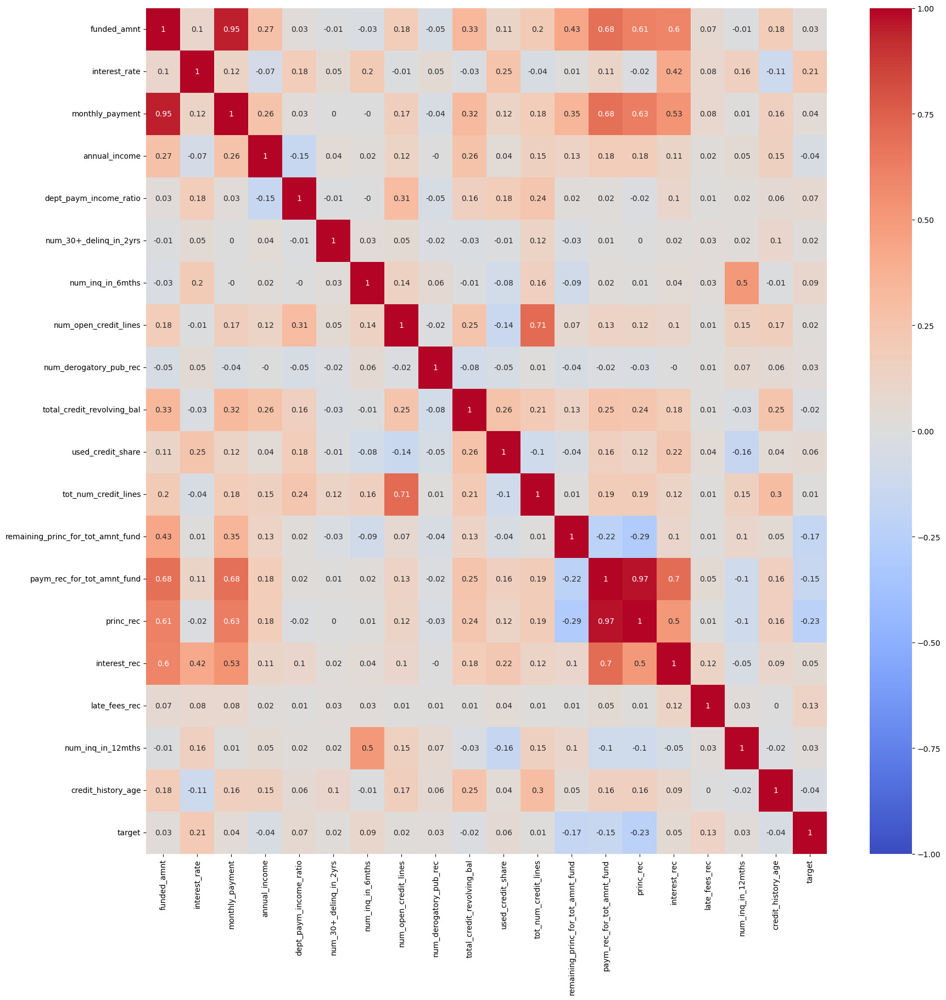

In [29]:
numeric_corr = numerical_data.corr().round(decimals=2)
plt.figure(figsize=(20, 20))
sns.heatmap(
    numeric_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

potential columns to reject because of big correlations:
- "monthly_payment",
- "tot_num_credit_lines"
- "paym_rec_for_tot_amnt_fund" or "princ_rec"

### VIF (Variance Inflation Factor) analysis to determine linearity degree between independent variables
$$ VIF_i = \frac{1}{1 - {R_i}^2} \;\;\;\;\;\;\; i = 1, 2 ... k $$

In [30]:
print( hf.VIF(customer_data_encoded.drop(columns='target')) )

const                                 139.69
funded_amnt                            60.52
interest_rate                           2.81
monthly_payment                        45.43
annual_income                           1.20
dept_paym_income_ratio                  1.32
num_30+_delinq_in_2yrs                  1.04
num_inq_in_6mths                        1.45
num_open_credit_lines                   2.30
num_derogatory_pub_rec                  1.04
total_credit_revolving_bal              1.41
used_credit_share                       1.39
tot_num_credit_lines                    2.33
remaining_princ_for_tot_amnt_fund       5.07
paym_rec_for_tot_amnt_fund            322.42
princ_rec                             186.28
interest_rec                           26.33
late_fees_rec                           1.03
num_inq_in_12mths                       1.50
credit_history_age                      1.27
emp_length_10+ years                    4.16
emp_length_2 years                      2.17
emp_length

In [31]:
"""dropping columns that have VIF > 10 because the linearity among the predictors might significantly affect quality of the model,
also there are cases that VIF > 10 and the correlation with another variable based on the correlation matrix is very high so that
confirms the validity of dropping those columns"""
"""
 - monthly_payment and funded_amnt are highly correlated and both have high VIF so dropping one of them
 - paym_rec_for_tot_amnt_fund and princ_rec are highly correlated and both have high VIF so dropping one of them,
   also paym_rec_for_tot_amnt_fund column is a sum of princ_rec and interest_rec so it's better to drop this column
 - loan_purpose_credit_card and loan_purpose_debt_consolidation both have hight VIF so dropping one of them
"""
cols_to_drop = ['monthly_payment', 'paym_rec_for_tot_amnt_fund', 'loan_purpose_debt_consolidation']
print( hf.VIF( customer_data_encoded.drop(columns=[*cols_to_drop, 'target']) ) )

const                                 58.33
funded_amnt                            5.45
interest_rate                          1.87
annual_income                          1.20
dept_paym_income_ratio                 1.31
num_30+_delinq_in_2yrs                 1.04
num_inq_in_6mths                       1.44
num_open_credit_lines                  2.30
num_derogatory_pub_rec                 1.04
total_credit_revolving_bal             1.41
used_credit_share                      1.39
tot_num_credit_lines                   2.33
remaining_princ_for_tot_amnt_fund      3.32
princ_rec                              4.43
interest_rec                           2.48
late_fees_rec                          1.03
num_inq_in_12mths                      1.50
credit_history_age                     1.27
emp_length_10+ years                   4.16
emp_length_2 years                     2.17
emp_length_3 years                     2.08
emp_length_4 years                     1.83
emp_length_5 years              

In [32]:
customer_data_encoded = customer_data_encoded.drop( columns=cols_to_drop )
customer_data_encoded.shape

(39935, 57)

In [33]:
customer_data_encoded.head(10)

,funded_amnt,interest_rate,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,credit_history_age,target,emp_length_10+ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length_< 1 year,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,5000,16.99,40000.00,15.75,1,0,8,0,4437,65.30,22,2395.13,2604.87,1160.55,0.00,1,17,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
1,1500,18.25,63749.00,7.32,0,0,4,1,746,74.60,8,0.00,1500.00,455.93,0.00,0,25,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0
2,33425,20.49,75000.00,31.58,0,2,16,0,38198,58.60,51,0.00,33425.00,6860.09,0.00,2,18,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,15000,17.09,95000.00,12.62,0,0,7,0,8841,65.50,10,11332.27,3667.73,3822.49,0.00,3,6,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
4,20000,18.25,70000.00,26.97,0,2,15,0,21524,47.80,28,0.00,20000.00,5468.90,0.00,2,19,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0
5,15000,13.67,80000.00,10.36,0,1,11,0,7297,56.60,13,0.00,15000.00,3369.44,0.00,1,7,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
6,19000,9.16,54800.00,27.24,0,0,20,0,20674,46.40,32,0.00,9911.35,2191.38,0.00,3,10,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
7,3000,7.49,73000.00,8.93,0,0,5,0,2875,56.40,16,0.00,3000.00,288.47,0.00,1,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
8,8400,11.99,44000.00,26.16,0,1,14,0,12693,79.30,27,4578.19,3821.81,1174.47,0.00,3,15,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
9,12000,16.99,42000.00,24.71,0,0,10,0,9875,44.90,15,0.00,12000.00,1054.33,0.00,0,4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1


In [34]:
"""Cleaning feature names by replacing special characters with more suitable strings due to further problems that occured for XGBoost with such names"""
def clean_feature_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .astype(str)
        .str.replace('<', '_lt_', regex=False)
        .str.replace('>', '_gt_', regex=False)
        .str.replace('[', '_', regex=False)
        .str.replace(']', '_', regex=False)
        .str.replace('+', '_plus_', regex=False)
    )
    return df

customer_data_encoded = clean_feature_names(customer_data_encoded)
customer_data_encoded.head(10)

,funded_amnt,interest_rate,annual_income,dept_paym_income_ratio,num_30_plus__delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,credit_history_age,target,emp_length_10_plus_ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length__lt_ 1 year,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,5000,16.99,40000.00,15.75,1,0,8,0,4437,65.30,22,2395.13,2604.87,1160.55,0.00,1,17,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
1,1500,18.25,63749.00,7.32,0,0,4,1,746,74.60,8,0.00,1500.00,455.93,0.00,0,25,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0
2,33425,20.49,75000.00,31.58,0,2,16,0,38198,58.60,51,0.00,33425.00,6860.09,0.00,2,18,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,15000,17.09,95000.00,12.62,0,0,7,0,8841,65.50,10,11332.27,3667.73,3822.49,0.00,3,6,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
4,20000,18.25,70000.00,26.97,0,2,15,0,21524,47.80,28,0.00,20000.00,5468.90,0.00,2,19,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0
5,15000,13.67,80000.00,10.36,0,1,11,0,7297,56.60,13,0.00,15000.00,3369.44,0.00,1,7,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
6,19000,9.16,54800.00,27.24,0,0,20,0,20674,46.40,32,0.00,9911.35,2191.38,0.00,3,10,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
7,3000,7.49,73000.00,8.93,0,0,5,0,2875,56.40,16,0.00,3000.00,288.47,0.00,1,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
8,8400,11.99,44000.00,26.16,0,1,14,0,12693,79.30,27,4578.19,3821.81,1174.47,0.00,3,15,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
9,12000,16.99,42000.00,24.71,0,0,10,0,9875,44.90,15,0.00,12000.00,1054.33,0.00,0,4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1


In [35]:
customer_data_encoded['target'].value_counts()

target
0    34775
1     5160
Name: count, dtype: int64

### Scaling numerical data (MinMax scaling)

In [36]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()
cols_to_transform = customer_data_encoded.loc[:, :'credit_history_age'].columns

customer_data_scaled = customer_data_encoded.copy()
customer_data_scaled[cols_to_transform] = minmax_scaler.fit_transform( customer_data_scaled[cols_to_transform] )
customer_data_scaled.head()

,funded_amnt,interest_rate,annual_income,dept_paym_income_ratio,num_30_plus__delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,credit_history_age,target,emp_length_10_plus_ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length__lt_ 1 year,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,0.10,0.45,0.00,0.32,0.04,0.00,0.10,0.00,0.01,0.49,0.16,0.06,0.07,0.04,0.00,0.04,0.29,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
1,0.02,0.50,0.01,0.15,0.00,0.00,0.04,0.02,0.00,0.56,0.05,0.00,0.04,0.02,0.00,0.00,0.43,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0
2,0.83,0.59,0.01,0.64,0.00,0.12,0.22,0.00,0.05,0.44,0.38,0.00,0.84,0.25,0.00,0.08,0.31,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,0.36,0.46,0.01,0.26,0.00,0.00,0.09,0.00,0.01,0.49,0.07,0.29,0.09,0.14,0.00,0.12,0.10,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
4,0.49,0.50,0.01,0.55,0.00,0.12,0.20,0.00,0.03,0.36,0.20,0.00,0.50,0.20,0.00,0.08,0.33,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0


#### Using Lasso Logistic Regression for feature selection

In [37]:
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.model_selection import train_test_split

X = customer_data_scaled.drop(columns='target')
y = customer_data_scaled['target']

"""Splitting data into training (60 %), validation (20 %), and test (20 %) sets"""
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=random_state,
    stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid,
    y_train_valid,
    test_size=0.25,
    random_state=random_state,
    stratify=y_train_valid
)
LogisticRegressionCV()
"""Using Lasso (L1) regularization with Logistic Regression to select features with non-zero coefficients"""
logrCV_model = LogisticRegressionCV(
    solver='saga',
    penalty='l1',
    class_weight='balanced',
    Cs=np.logspace(-4, 0, 20), 
    scoring='roc_auc',
	max_iter=2000,
    tol=1e-4,
	cv=5,
	random_state=random_state
)
logrCV_model.fit(
    X=X_train,
    y=y_train
)

col_names = X_train.columns
threshold_ = 1e-3
coeffs = logrCV_model.coef_.ravel()
selected_features_mask = np.abs(coeffs) > threshold_

# selected feature names
selected_features = col_names[selected_features_mask]
C = logrCV_model.C_[0]
print(f"C: {C:.2f}")
print(f"Lambda: {(1/C):.2f}")
print("\nFeatures with zeroed coeffs:")
print( *col_names[~selected_features_mask].to_list(), sep=",\n" )
print("\nSelected features:")
selected_features.to_list(), len(selected_features)

C: 1.00
Lambda: 1.00

Features with zeroed coeffs:
annual_income,
num_30_plus__delinq_in_2yrs,
num_open_credit_lines,
num_derogatory_pub_rec,
tot_num_credit_lines,
emp_length_10_plus_ years,
emp_length_2 years,
home_ownership_status_OTHER,
loan_purpose_educational,
loan_purpose_house,
loan_purpose_renewable_energy,
loan_purpose_wedding

Selected features:


(['funded_amnt',
  'interest_rate',
  'dept_paym_income_ratio',
  'num_inq_in_6mths',
  'total_credit_revolving_bal',
  'used_credit_share',
  'remaining_princ_for_tot_amnt_fund',
  'princ_rec',
  'interest_rec',
  'late_fees_rec',
  'num_inq_in_12mths',
  'credit_history_age',
  'emp_length_3 years',
  'emp_length_4 years',
  'emp_length_5 years',
  'emp_length_6 years',
  'emp_length_7 years',
  'emp_length_8 years',
  'emp_length_9 years',
  'emp_length__lt_ 1 year',
  'home_ownership_status_OWN',
  'home_ownership_status_RENT',
  'verification_status_Source Verified',
  'verification_status_Verified',
  'loan_purpose_credit_card',
  'loan_purpose_home_improvement',
  'loan_purpose_major_purchase',
  'loan_purpose_medical',
  'loan_purpose_moving',
  'loan_purpose_other',
  'loan_purpose_small_business',
  'loan_purpose_vacation',
  'initial_list_status_w',
  'disbursement_method_DirectPay',
  'loan_term_months_60',
  'region_code_1',
  'region_code_2',
  'region_code_3',
  'region_

### Logistic Regression Model
$$ p=P(Y=1|X)= \frac{1}{1+\exp{(-(\beta_0+\beta_1 X_1+...+\beta_k X_k))}}

In [38]:
"""Selecting only features with non-zero coefficients from Logistic Regression with L1 regularization"""
"""Final X_train, X_valid, X_test"""
X_train_valid = X_train_valid[selected_features]
X_train = X_train[selected_features]
X_valid = X_valid[selected_features]
X_test = X_test[selected_features]

start_time = time.time()
log_reg_model = LogisticRegression(
    class_weight='balanced',
    penalty='l2',
    random_state=random_state
)
log_reg_model.fit(
    X=X_train,
    y=y_train,
)
end_time = time.time()
print(f"Logistic Regression training time: {(end_time - start_time):.2f} seconds")

Logistic Regression training time: 0.11 seconds


beta = 2, optimal_idx = 6986


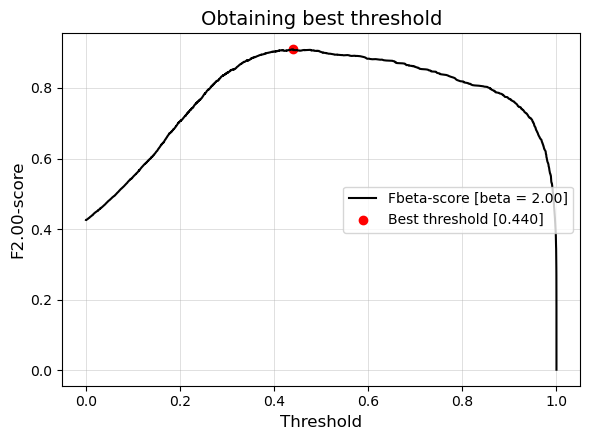

LR optimal threshold: 0.4405
LR best Fbeta-score: 0.9095


In [39]:
y_probs_LR_train = log_reg_model.predict_proba(X_train)
y_probs_LR_valid = log_reg_model.predict_proba(X_valid)
y_probs_LR_test = log_reg_model.predict_proba(X_test)

# Obtaining best threshold for Logistic Regression based on Fbeta-score
beta = 2
lr_best_threshold, lr_best_score, lr_beta = hf.find_optimal_threshold(
    y_true=y_valid,
    y_proba=y_probs_LR_valid[:, 1],
    beta=beta
)
print(f'LR optimal threshold: {lr_best_threshold:.4f}')
print(f'LR best Fbeta-score: {lr_best_score:.4f}')

y_pred_LR_train = np.where( y_probs_LR_train[:, 1] > lr_best_threshold, 1, 0 ) # log_reg_model.predict(X_train)
y_pred_LR_valid = np.where( y_probs_LR_valid[:, 1] > lr_best_threshold, 1, 0 ) # log_reg_model.predict(X_valid)
y_pred_LR_test = np.where( y_probs_LR_test[:, 1] > lr_best_threshold, 1, 0 ) # log_reg_model.predict(X_test)

#### Confusion Matrices

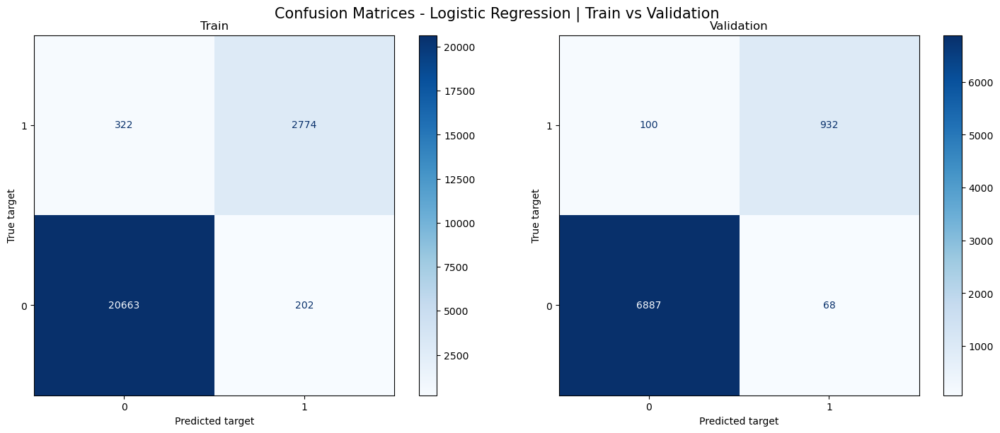

Train data:
Accuracy: 0.978
                  0        1  accuracy  macro avg  weighted avg
precision     0.985    0.932     0.978      0.958         0.978
recall        0.990    0.896     0.978      0.943         0.978
f1-score      0.987    0.914     0.978      0.951         0.978
support   20865.000 3096.000     0.978  23961.000     23961.000


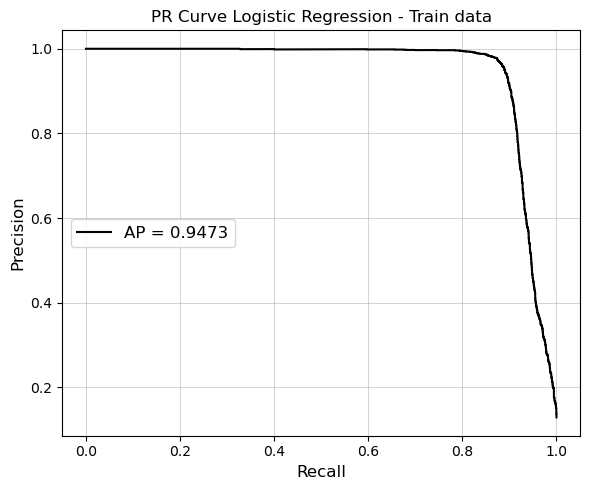


Validation data:
Accuracy: 0.979
                 0        1  accuracy  macro avg  weighted avg
precision    0.986    0.932     0.979      0.959         0.979
recall       0.990    0.903     0.979      0.947         0.979
f1-score     0.988    0.917     0.979      0.953         0.979
support   6955.000 1032.000     0.979   7987.000      7987.000


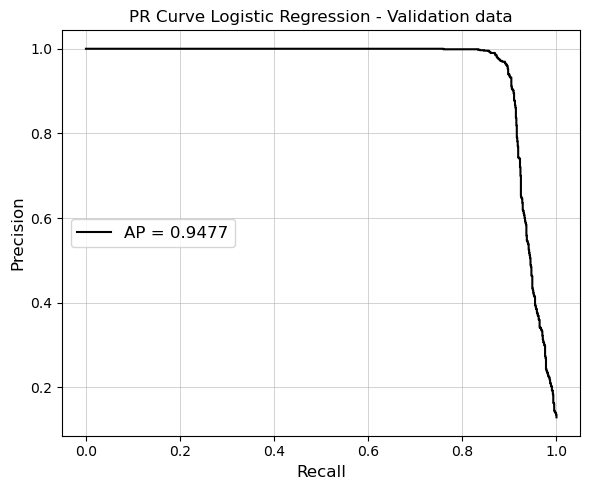

,0,1,accuracy,macro avg,weighted avg
precision,0.99,0.93,0.98,0.96,0.98
recall,0.99,0.90,0.98,0.95,0.98
f1-score,0.99,0.92,0.98,0.95,0.98
support,6955.00,1032.00,0.98,7987.00,7987.00


In [40]:
cm_train_LR, cm_valid_LR = hf.display_confusion_matrix(
    y1_true=y_train,
	y1_pred=y_pred_LR_train,
	y2_true=y_valid,
	y2_pred=y_pred_LR_valid,
	title='Confusion Matrices - Logistic Regression | Train vs Validation',
	cmap='Blues',
	compare=['Train', 'Validation']
)
hf.quality_metrics(
    y_true=y_train,
	y_pred=y_pred_LR_train,
	y_probs=y_probs_LR_train[:, 1],
	label='Train data',
	pr_curve_title='PR Curve Logistic Regression - Train data'
)
hf.quality_metrics(
    y_true=y_valid,
	y_pred=y_pred_LR_valid,
	y_probs=y_probs_LR_valid[:, 1],
	label='\nValidation data',
	pr_curve_title='PR Curve Logistic Regression - Validation data'
)

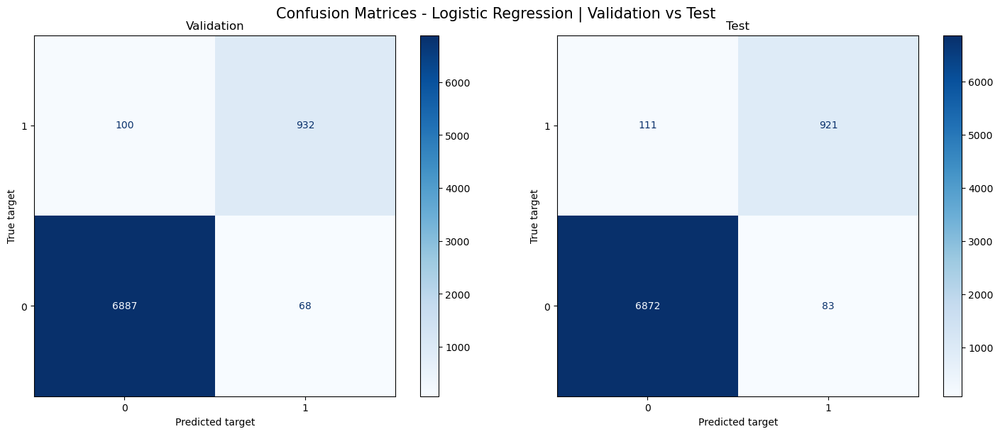

Validation data:
Accuracy: 0.979
                 0        1  accuracy  macro avg  weighted avg
precision    0.986    0.932     0.979      0.959         0.979
recall       0.990    0.903     0.979      0.947         0.979
f1-score     0.988    0.917     0.979      0.953         0.979
support   6955.000 1032.000     0.979   7987.000      7987.000


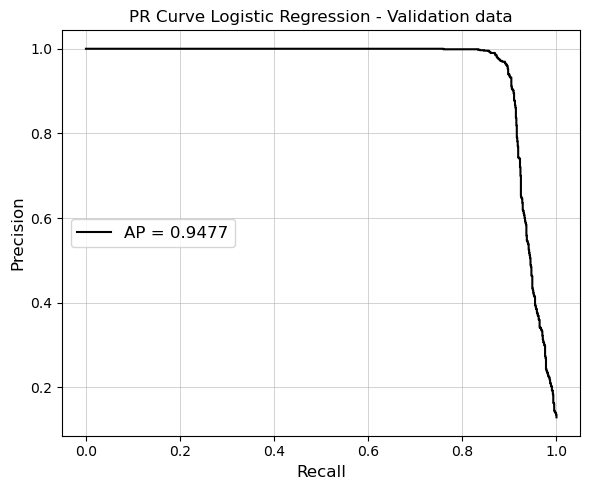


Test data:
Accuracy: 0.976
                 0        1  accuracy  macro avg  weighted avg
precision    0.984    0.917     0.976      0.951         0.975
recall       0.988    0.892     0.976      0.940         0.976
f1-score     0.986    0.905     0.976      0.945         0.976
support   6955.000 1032.000     0.976   7987.000      7987.000


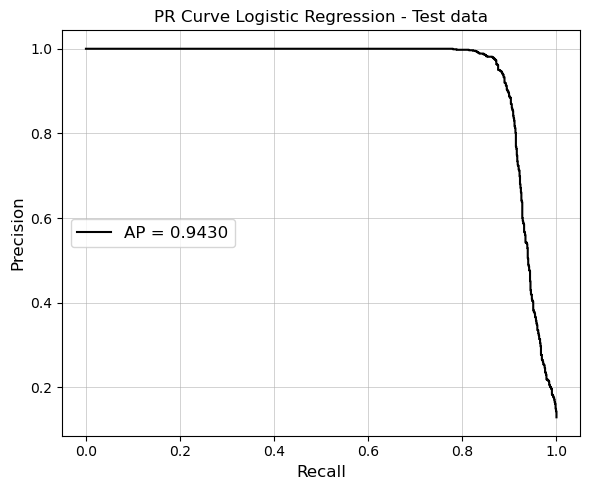

In [41]:
cm_valid_LR, cm_test_LR = hf.display_confusion_matrix(
    y1_true=y_valid,
	y1_pred=y_pred_LR_valid,
	y2_true=y_test,
	y2_pred=y_pred_LR_test,
	title='Confusion Matrices - Logistic Regression | Validation vs Test',
	cmap='Blues',
	compare=['Validation', 'Test']
)
hf.quality_metrics(
    y_true=y_valid,
    y_pred=y_pred_LR_valid,
    y_probs=y_probs_LR_valid[:, 1],
    label='Validation data',
    pr_curve_title='PR Curve Logistic Regression - Validation data'
)
clf_report_lr_test = hf.quality_metrics(
    y_true=y_test,
	y_pred=y_pred_LR_test,
	y_probs=y_probs_LR_test[:, 1],
	label='\nTest data',
	pr_curve_title='PR Curve Logistic Regression - Test data'
)

#### Feature importances and SHAP values for Logistic Regression model

Calculating feature importances for Logistic regression model ...


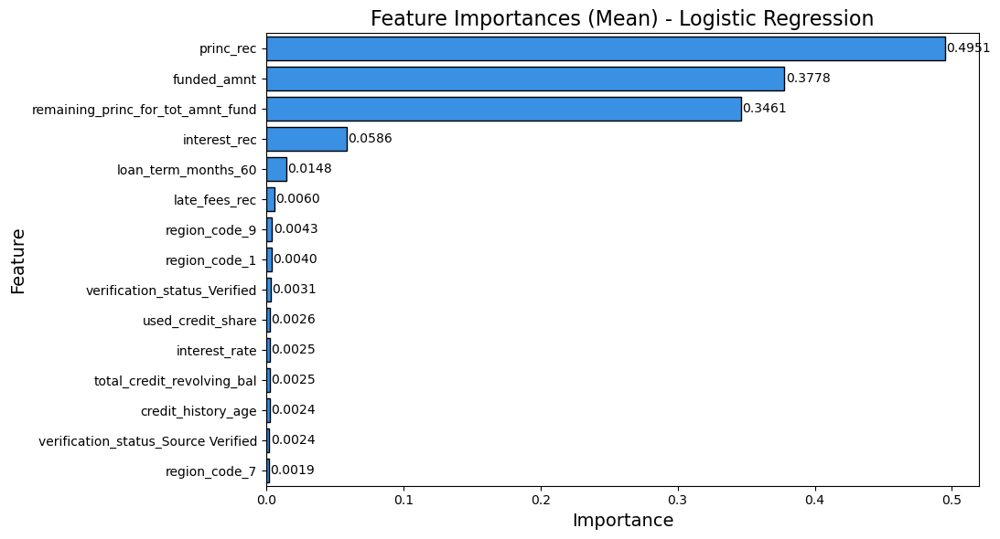

In [42]:
"""Feature importance for Logistic Regression model"""
lr_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
    threshold=lr_best_threshold,
	beta=lr_beta
)
lr_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
    model=log_reg_model,
	model_name='Logistic Regression',
	X_data=X_valid,
	y_data=y_valid,
	n_reps=5,
    scoring=lr_scorer,
	max_num_features=15,
	n_jobs=-1
)

Calculating SHAP values for Logistic regression model ...
(.values =
array([[-2.88925257e+00,  3.16804501e-01, -3.65779155e-02, ...,
        -1.75362265e-02, -1.91210885e-02,  2.10918348e-01],
       [ 3.66876203e+00,  2.77875170e-02, -7.50097880e-03, ...,
        -1.75362265e-02, -1.91210885e-02,  2.10918348e-01],
       [ 9.03441033e+00,  1.38367928e-01, -1.31131662e-02, ...,
        -1.75362265e-02, -1.91210885e-02, -4.01749234e-02],
       ...,
       [-1.69688628e+00,  4.88955304e-03,  4.11044349e-03, ...,
        -1.75362265e-02, -1.91210885e-02, -4.01749234e-02],
       [ 9.16631585e-02,  2.37220114e-01, -1.74364858e-03, ...,
        -1.75362265e-02, -1.91210885e-02, -4.01749234e-02],
       [ 1.88021259e+00, -1.11834215e-01,  2.80590020e-02, ...,
        -1.75362265e-02, -1.91210885e-02,  2.10918348e-01]])

.base_values =
array([-1.3639148, -1.3639148, -1.3639148, ..., -1.3639148, -1.3639148,
       -1.3639148])

.data =
array([[0.23273657, 0.76051402, 0.20732452, ..., 0.      

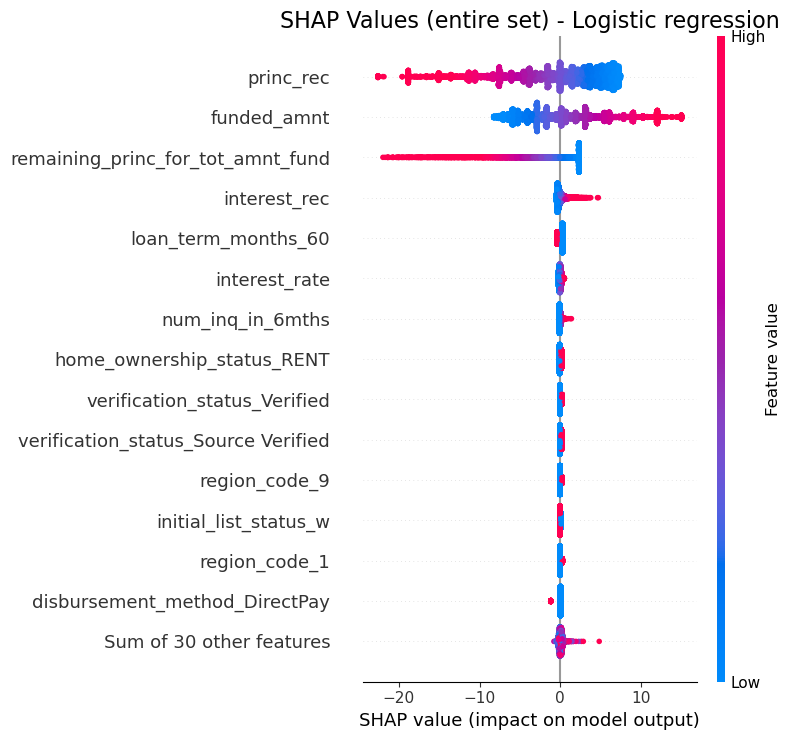

Sample pred: 1


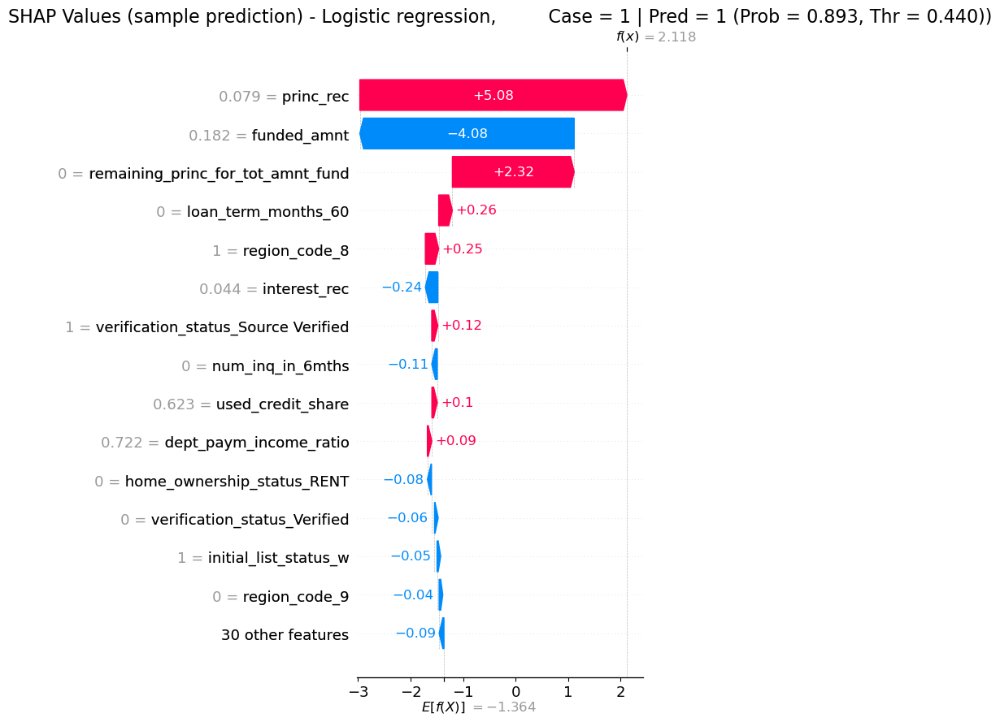

In [ ]:
hf.plot_shap_values(
    model=log_reg_model,
    model_name='Logistic Regression',
    X_train=X_train,
	y_train=y_train,
    X_valid=X_test,
    y_valid=y_test,
    threshold=lr_best_threshold,
    random_state=random_state
)

#### PCA Visualization - Logistic Regression

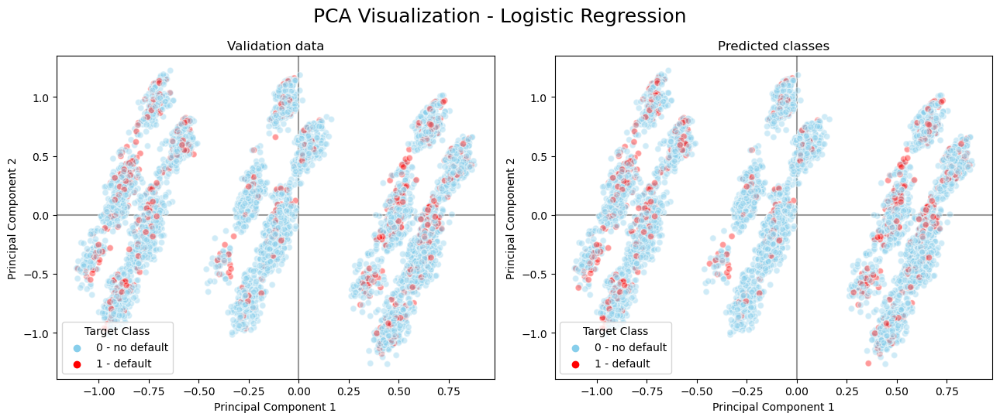

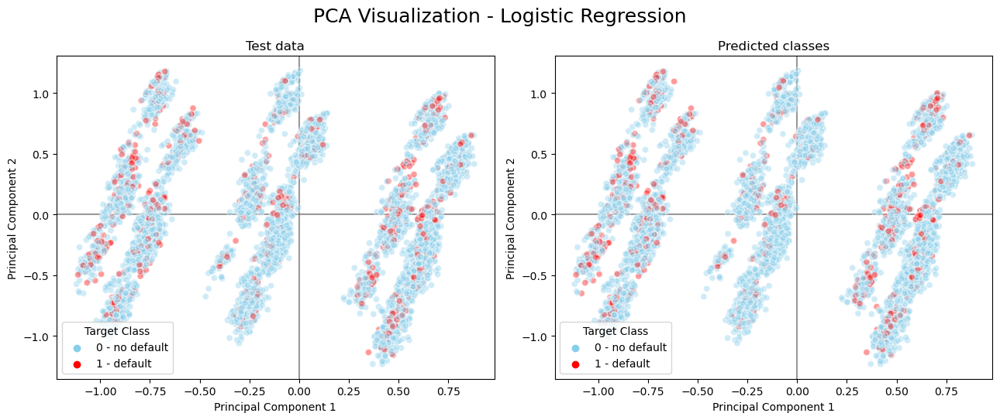

In [44]:
colors_dict = {0: 'skyblue', 1: 'red'}
class_names_dict = {0: 'no default', 1: 'default'}
hf.pca_visualization(
    X_train=X_train,
    X_new=X_valid,
    y_new_true=y_valid,
    y_new_pred=y_pred_LR_valid,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Logistic Regression',
    valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
    X_train=X_train,
    X_new=X_test,
    y_new_true=y_test,
    y_new_pred=y_pred_LR_test,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Logistic Regression',
    valid_or_test='Test',
    alpha=0.4
)

Logistic Regression training time: 0.03 seconds


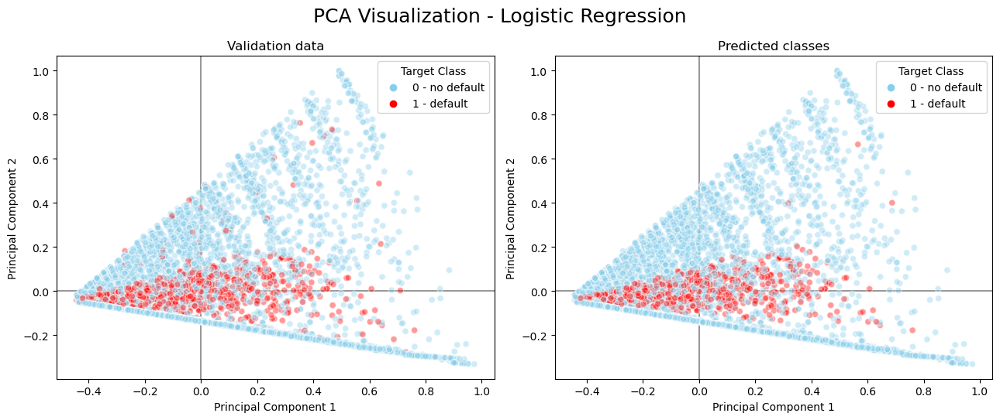

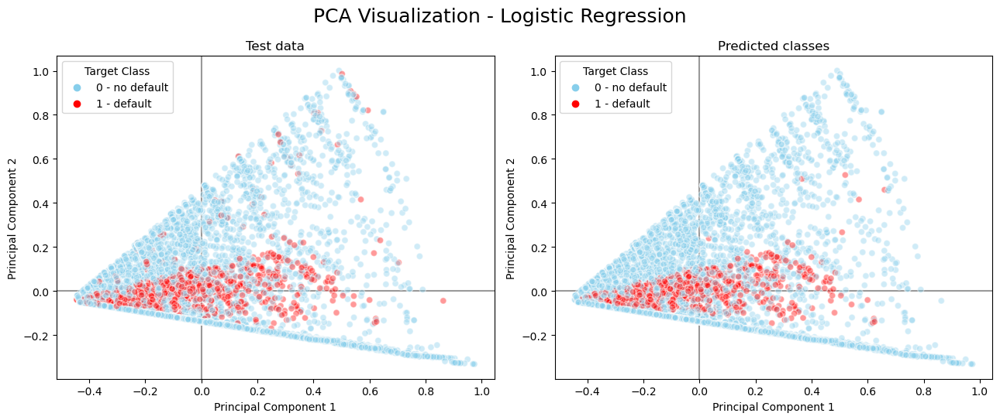

In [45]:
"""PCA for most important features based on feature importance plot"""
lr_most_important_feats = lr_feat_names_sorted_desc_by_importance[:4]
X_LR_train_important_feats = X_train[ lr_most_important_feats ]
X_LR_valid_important_feats = X_valid[ lr_most_important_feats ]
X_LR_test_important_feats = X_test[ lr_most_important_feats ]

"""Building Logistic Regression model using only most important features only for PCA visualization purposes"""
start_time = time.time()
lr_model_important_feats = LogisticRegression( **log_reg_model.get_params() )
lr_model_important_feats.fit(
    X=X_LR_train_important_feats,
    y=y_train
)
end_time = time.time()
print(f"Logistic Regression training time: {(end_time - start_time):.2f} seconds")

y_pred_LR_valid_imp_feats = lr_model_important_feats.predict( X_LR_valid_important_feats )
y_pred_LR_test_imp_feats = lr_model_important_feats.predict( X_LR_test_important_feats )

hf.pca_visualization(
	X_train=X_LR_train_important_feats,
	X_new=X_LR_valid_important_feats,
	y_new_true=y_valid,
	y_new_pred=y_pred_LR_valid_imp_feats,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Logistic Regression',
	valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
	X_train=X_LR_train_important_feats,
	X_new=X_LR_test_important_feats,
	y_new_true=y_test,
	y_new_pred=y_pred_LR_test_imp_feats,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Logistic Regression',
	valid_or_test='Test',
	alpha=0.4
)

### XGBoost algorithm

In [46]:
import torch

"""setting device"""
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [47]:
import xgboost as xgb

val_counts = y_train.value_counts()
class_freq_ratio = val_counts.loc[0] / val_counts.loc[1]

start_time = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.01,
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=class_freq_ratio,
    early_stopping_rounds=50,
    random_state=random_state
)
xgb_model.fit(
    X=X_train,
    y=y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=50
)
end_time = time.time()
print(f"XGBoost training time: {(end_time - start_time):.2f} seconds")

[0]	validation_0-logloss:0.68441
[50]	validation_0-logloss:0.39559
[100]	validation_0-logloss:0.25360
[150]	validation_0-logloss:0.17695
[199]	validation_0-logloss:0.13341
XGBoost training time: 1.32 seconds


beta = 2, optimal_idx = 4198


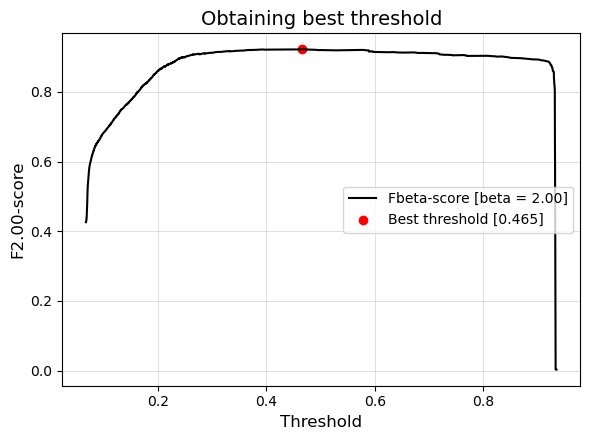

XGB optimal threshold: 0.4653
XGB best Fbeta-score: 0.9222


In [48]:
# Probabilities
y_probs_XGB_train = xgb_model.predict_proba(X_train)
y_probs_XGB_valid = xgb_model.predict_proba(X_valid)
y_probs_XGB_test = xgb_model.predict_proba(X_test)

# Obtaining best threshold for XGBoost based on recall
xgb_best_threshold, xgb_best_score, xgb_beta = hf.find_optimal_threshold(
    y_true=y_valid,
    y_proba=y_probs_XGB_valid[:, 1],
    beta=beta
)
print(f'XGB optimal threshold: {xgb_best_threshold:.4f}')
print(f'XGB best Fbeta-score: {xgb_best_score:.4f}')

# Predictions (labels)
y_pred_XGB_train = np.where(y_probs_XGB_train[:, 1] > xgb_best_threshold, 1, 0) # xgb_model.predict(X_train)
y_pred_XGB_valid = np.where(y_probs_XGB_valid[:, 1] > xgb_best_threshold, 1, 0) # xgb_model.predict(X_valid)
y_pred_XGB_test = np.where(y_probs_XGB_test[:, 1] > xgb_best_threshold, 1, 0) # xgb_model.predict(X_test)

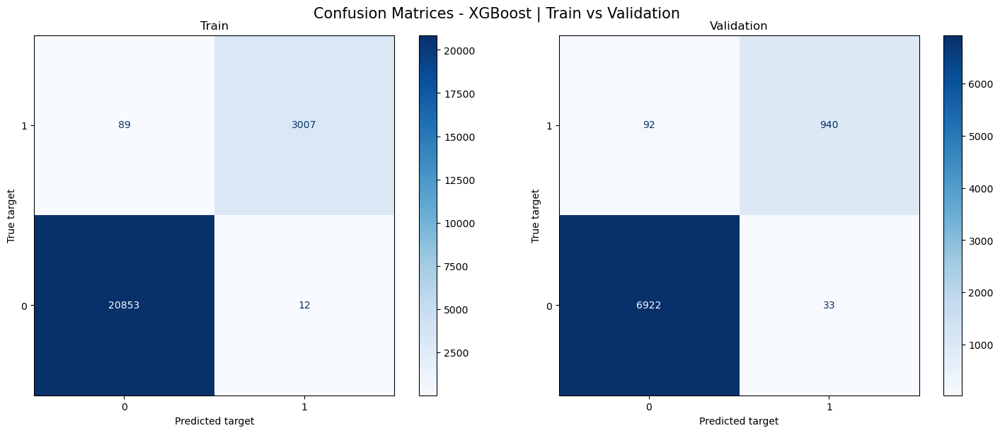

Train data:
Accuracy: 0.996
                  0        1  accuracy  macro avg  weighted avg
precision     0.996    0.996     0.996      0.996         0.996
recall        0.999    0.971     0.996      0.985         0.996
f1-score      0.998    0.983     0.996      0.991         0.996
support   20865.000 3096.000     0.996  23961.000     23961.000


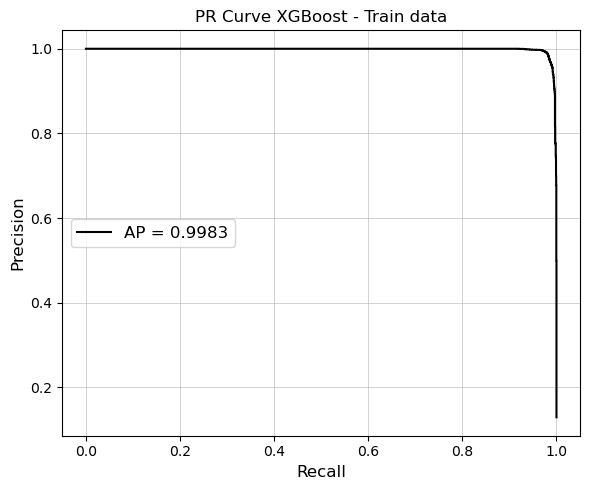


Validation data:
Accuracy: 0.984
                 0        1  accuracy  macro avg  weighted avg
precision    0.987    0.966     0.984      0.976         0.984
recall       0.995    0.911     0.984      0.953         0.984
f1-score     0.991    0.938     0.984      0.964         0.984
support   6955.000 1032.000     0.984   7987.000      7987.000


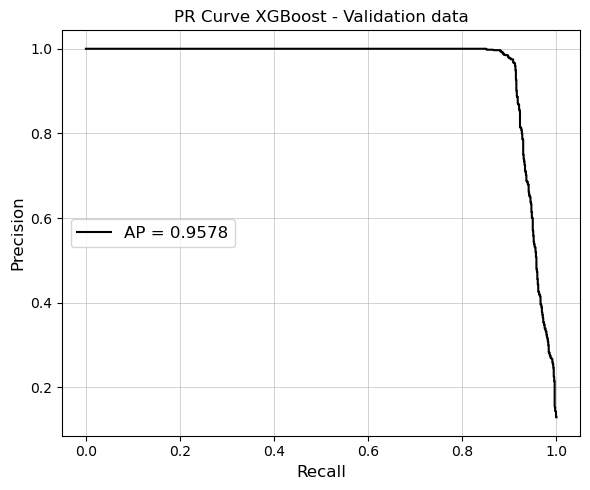

,0,1,accuracy,macro avg,weighted avg
precision,0.99,0.97,0.98,0.98,0.98
recall,0.99,0.91,0.98,0.95,0.98
f1-score,0.99,0.94,0.98,0.96,0.98
support,6955.00,1032.00,0.98,7987.00,7987.00


In [49]:
cm_train_XGB, cm_valid_XGB = hf.display_confusion_matrix(
    y1_true=y_train,
    y1_pred=y_pred_XGB_train,
    y2_true=y_valid,
    y2_pred=y_pred_XGB_valid,
    title='Confusion Matrices - XGBoost | Train vs Validation',
    cmap="Blues",
    compare=['Train', 'Validation']
)
hf.quality_metrics(
    y_true=y_train,
	y_pred=y_pred_XGB_train,
    y_probs=y_probs_XGB_train[:, 1],
    label='Train data',
    pr_curve_title='PR Curve XGBoost - Train data'
)
hf.quality_metrics(
    y_true=y_valid,
    y_pred=y_pred_XGB_valid,
	y_probs=y_probs_XGB_valid[:, 1],
    label='\nValidation data',
    pr_curve_title='PR Curve XGBoost - Validation data'
)

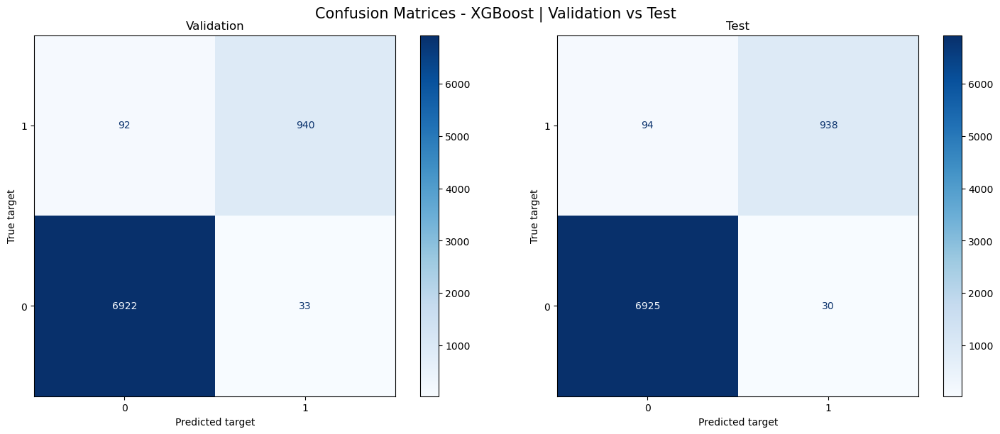

Validation data:
Accuracy: 0.984
                 0        1  accuracy  macro avg  weighted avg
precision    0.987    0.966     0.984      0.976         0.984
recall       0.995    0.911     0.984      0.953         0.984
f1-score     0.991    0.938     0.984      0.964         0.984
support   6955.000 1032.000     0.984   7987.000      7987.000


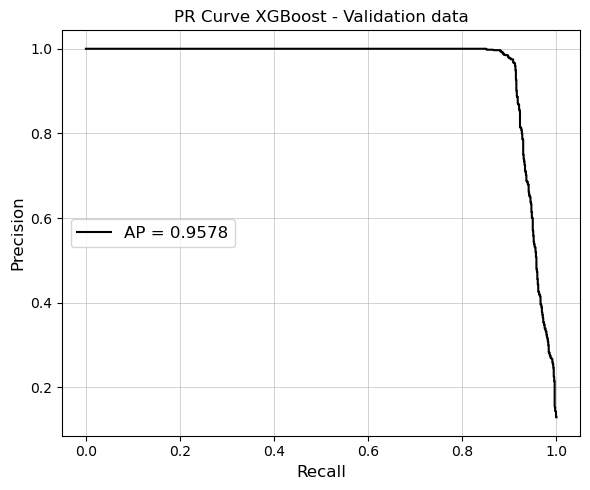


Test data:
Accuracy: 0.984
                 0        1  accuracy  macro avg  weighted avg
precision    0.987    0.969     0.984      0.978         0.984
recall       0.996    0.909     0.984      0.952         0.984
f1-score     0.991    0.938     0.984      0.965         0.984
support   6955.000 1032.000     0.984   7987.000      7987.000


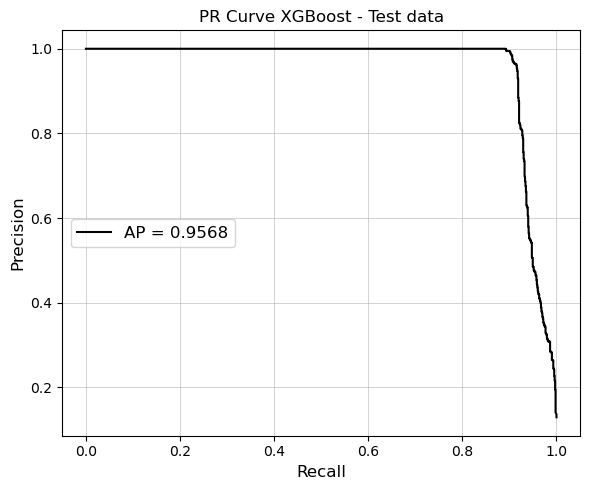

In [50]:
cm_valid_XGB, cm_test_XGB = hf.display_confusion_matrix(
    y1_true=y_valid,
    y1_pred=y_pred_XGB_valid,
    y2_true=y_test,
    y2_pred=y_pred_XGB_test,
    title='Confusion Matrices - XGBoost | Validation vs Test',
    cmap="Blues",
    compare=['Validation', 'Test']
)
hf.quality_metrics(
    y_true=y_valid,
    y_pred=y_pred_XGB_valid,
    y_probs=y_probs_XGB_valid[:, 1],
    label='Validation data',
    pr_curve_title='PR Curve XGBoost - Validation data'
)
clf_report_xgb_test = hf.quality_metrics(
    y_true=y_test,
    y_pred=y_pred_XGB_test,
    y_probs=y_probs_XGB_test[:, 1],
    label='\nTest data',
    pr_curve_title='PR Curve XGBoost - Test data'
)

#### Visualizing decision trees, feature importances and SHAP values for XGBoost model

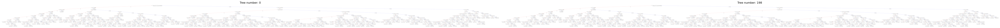

In [51]:
"""Plots decision trees for XGBoost model for chosen tree indices (first and last tree)"""
tree_indices = [0, xgb_model.best_iteration-1]
fig, axes = plt.subplots(1, len(tree_indices), figsize=(60, 80))
axes = axes.flatten()
for tree_i, ax in zip(tree_indices, axes):
    xgb.plot_tree(
        booster=xgb_model,
        tree_idx=tree_i,
        ax=ax
    )
    ax.set_title(f'Tree number: {tree_i}')
plt.tight_layout()
plt.show()

Calculating feature importances for Xgboost model ...


e:\Anaconda\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


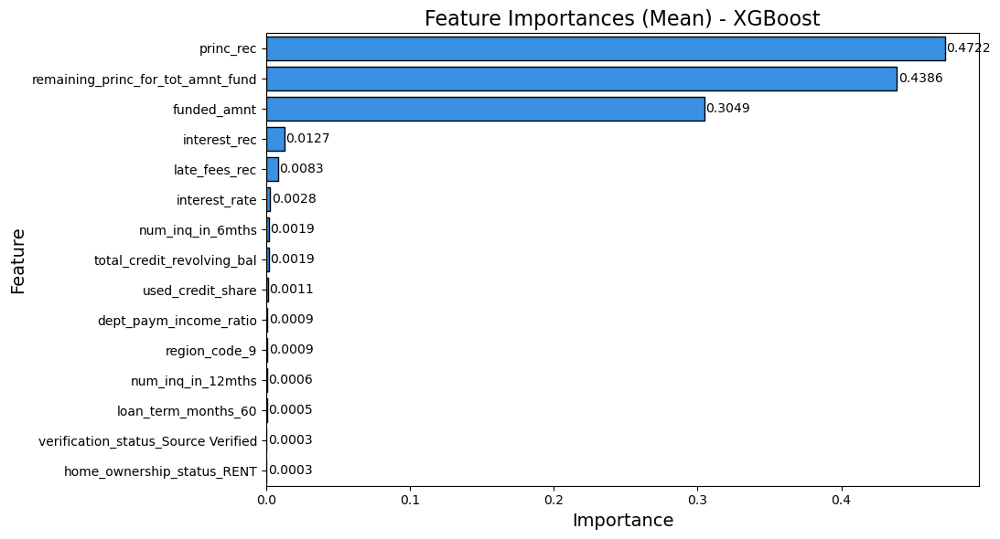

In [52]:
"""Feature importances for XGBoost model"""
xgb_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
    threshold=xgb_best_threshold,
    beta=xgb_beta
)
xgb_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
    model=xgb_model,
    model_name='XGBoost',
    X_data=X_valid,
    y_data=y_valid,
    n_reps=5,
    scoring=xgb_scorer,
    max_num_features=15,
    n_jobs=-1
)

Calculating SHAP values for Xgboost model ...
(.values =
array([[ 1.1324451e-01,  4.8091486e-02, -5.0822023e-02, ...,
        -1.1173799e-03, -8.5904851e-04,  1.9076250e-02],
       [ 6.5871760e-02, -4.9709575e-03, -1.1001035e-02, ...,
        -6.2705227e-04, -5.9637887e-04,  1.7199779e-03],
       [ 2.3067364e-01,  1.4108859e-01, -2.8490769e-02, ...,
         1.2743885e-04, -8.0494313e-03, -6.0852861e-04],
       ...,
       [ 1.9660962e-01,  3.3709299e-02, -1.4572112e-02, ...,
        -9.1640989e-04, -1.0604343e-03, -2.0242392e-03],
       [-3.8158882e-01, -7.8575879e-02, -9.9234814e-03, ...,
        -8.1462064e-04, -6.3730852e-04, -5.5559311e-04],
       [ 1.2431060e-01, -1.2157837e-02, -1.0888115e-02, ...,
        -2.3178980e-03, -9.6285448e-04,  1.5340835e-03]], dtype=float32)

.base_values =
array([0.00237321, 0.00237321, 0.00237321, ..., 0.00237321, 0.00237321,
       0.00237321], dtype=float32)

.data =
array([[0.23273657, 0.76051402, 0.20732452, ..., 0.        , 0.        ,
  

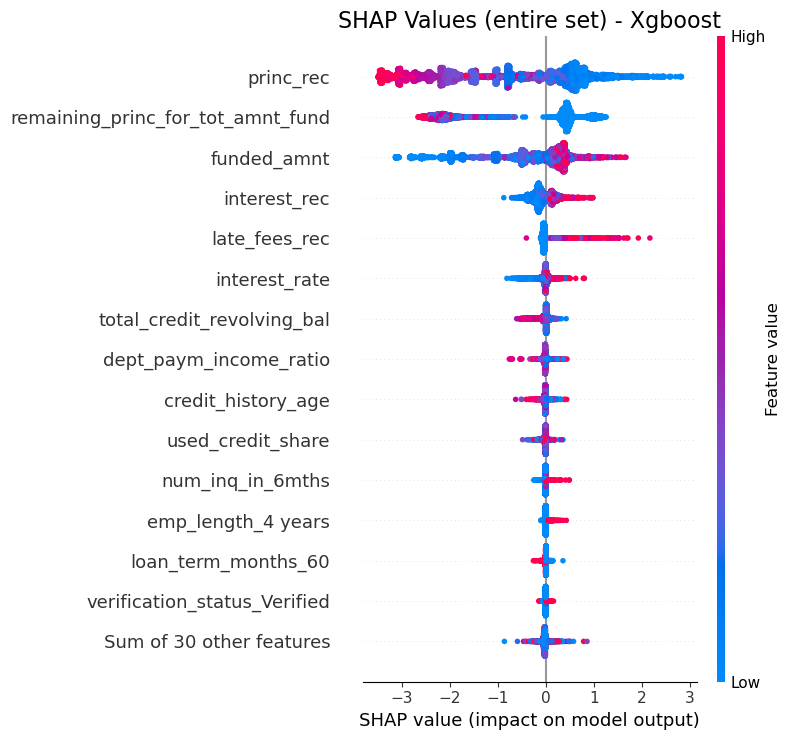

Sample pred: 1


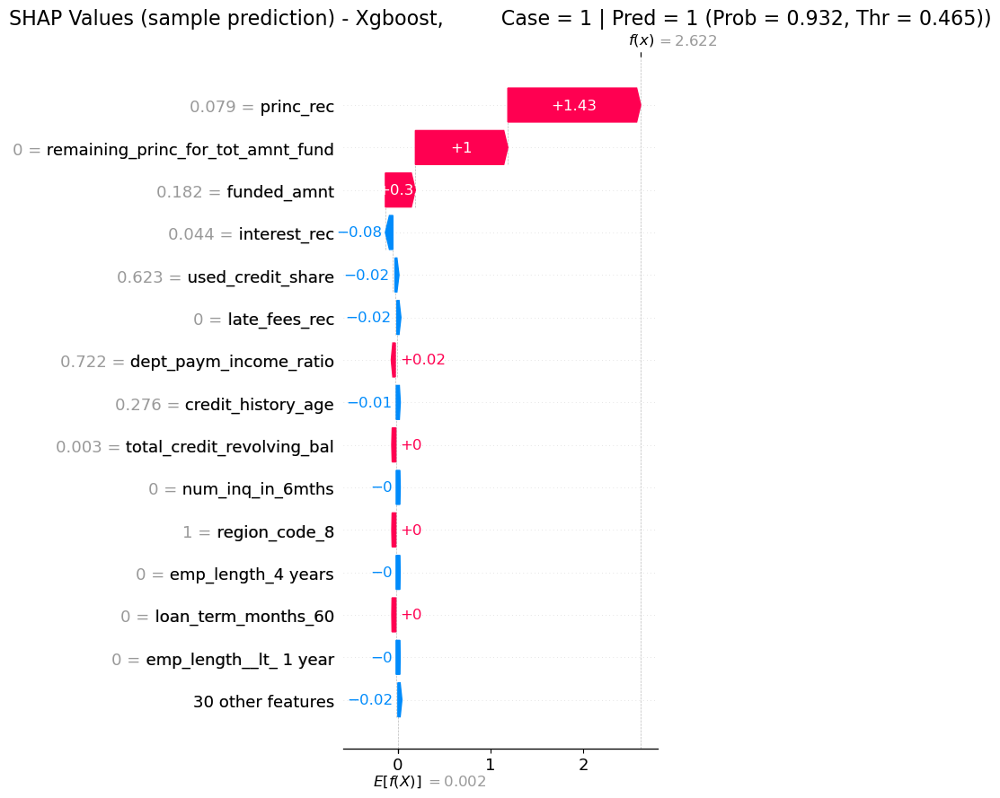

In [ ]:
hf.plot_shap_values(
    model=xgb_model,
    model_name='XGBoost',
    X_train=X_train,
    y_train=y_train,
    X_valid=X_test,
    y_valid=y_test,
    threshold=xgb_best_threshold,
    random_state=random_state
)

#### PCA Visualization - XGBoost

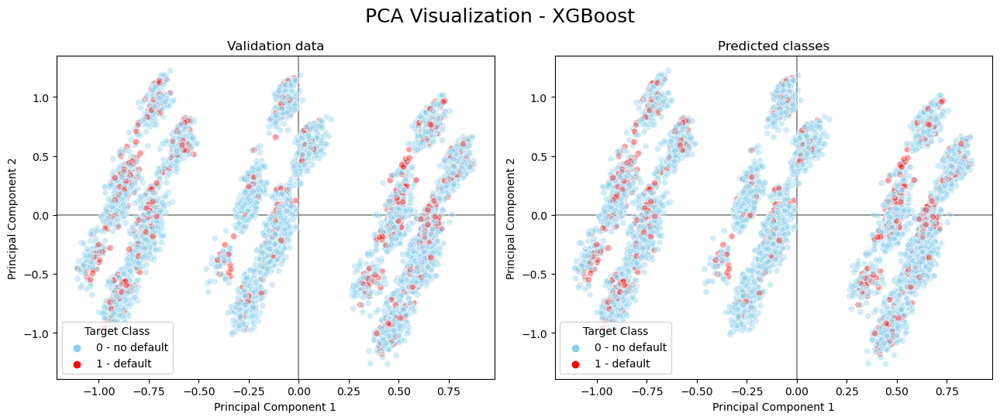

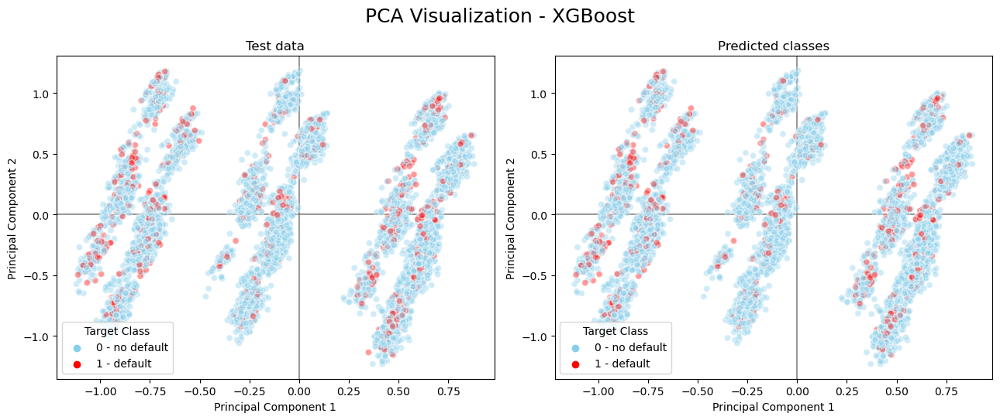

In [54]:
hf.pca_visualization(
    X_train=X_train,
    X_new=X_valid,
    y_new_true=y_valid,
    y_new_pred=y_pred_XGB_valid,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='XGBoost',
	valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
    X_train=X_train,
    X_new=X_test,
    y_new_true=y_test,
    y_new_pred=y_pred_XGB_test,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='XGBoost',
    valid_or_test='Test',
	alpha=0.4
)

[0]	validation_0-logloss:0.68452
[10]	validation_0-logloss:0.60667
[20]	validation_0-logloss:0.54148
[30]	validation_0-logloss:0.48608
[40]	validation_0-logloss:0.43858
[50]	validation_0-logloss:0.39749
[60]	validation_0-logloss:0.36180
[70]	validation_0-logloss:0.33049
[80]	validation_0-logloss:0.30301
[90]	validation_0-logloss:0.27892
[100]	validation_0-logloss:0.25772
[110]	validation_0-logloss:0.23910
[120]	validation_0-logloss:0.22257
[130]	validation_0-logloss:0.20784
[140]	validation_0-logloss:0.19476
[150]	validation_0-logloss:0.18313
[160]	validation_0-logloss:0.17278
[170]	validation_0-logloss:0.16350
[180]	validation_0-logloss:0.15506
[190]	validation_0-logloss:0.14753
[199]	validation_0-logloss:0.14150
XGBoost training time: 0.94 seconds


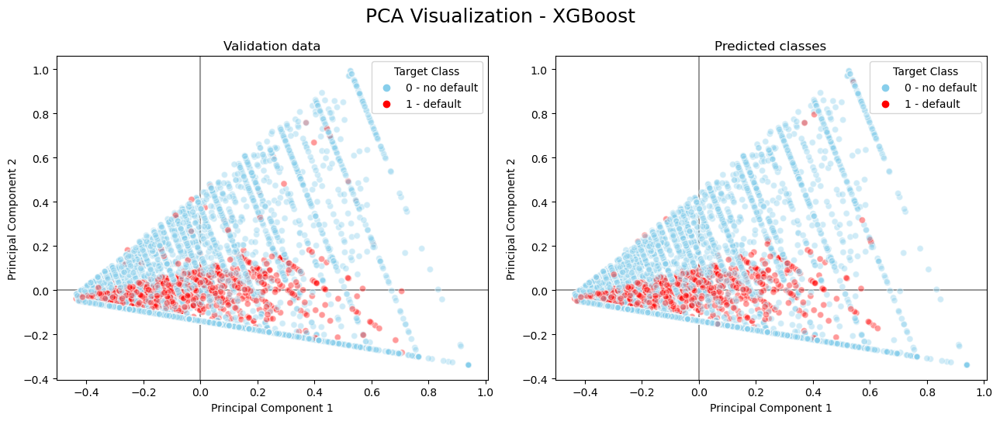

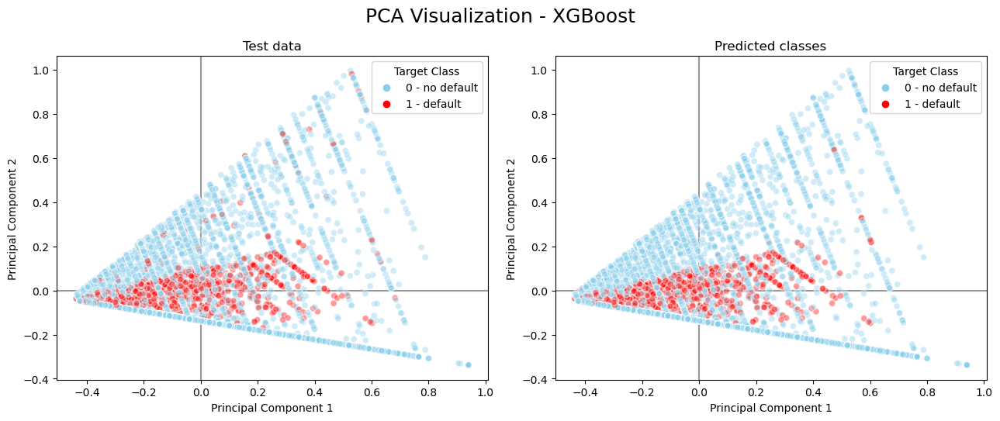

In [55]:
"""PCA for most important features based on feature importance plot"""
xgb_most_important_feats = xgb_feat_names_sorted_desc_by_importance[:3]
X_XGB_train_important_feats = X_train[ xgb_most_important_feats ]
X_XGB_valid_important_feats = X_valid[ xgb_most_important_feats ]
X_XGB_test_important_feats = X_test[ xgb_most_important_feats ]

"""Building XGBoost model using only most important features only for PCA visualization purposes"""
start_time = time.time()
xgb_model_important_feats = xgb.XGBClassifier( **xgb_model.get_params() )
xgb_model_important_feats.fit(
	X=X_XGB_train_important_feats,
	y=y_train,
	eval_set=[(X_XGB_valid_important_feats, y_valid)],
	verbose=10
)
end_time = time.time()
print(f"XGBoost training time: {(end_time - start_time):.2f} seconds")

y_pred_XGB_valid_imp_feats = xgb_model_important_feats.predict( X_XGB_valid_important_feats )
y_pred_XGB_test_imp_feats = xgb_model_important_feats.predict( X_XGB_test_important_feats )

hf.pca_visualization(
    X_train=X_XGB_train_important_feats,
    X_new=X_XGB_valid_important_feats,
    y_new_true=y_valid,
    y_new_pred=y_pred_XGB_valid_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='XGBoost',
	valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
    X_train=X_XGB_train_important_feats,
    X_new=X_XGB_test_important_feats,
    y_new_true=y_test,
    y_new_pred=y_pred_XGB_test_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='XGBoost',
	valid_or_test='Test',
	alpha=0.4
)

### Random Forest Classifier

In [56]:
from sklearn.ensemble import RandomForestClassifier

start_time = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced_subsample',
    random_state=random_state,
    n_jobs=-1
)
rf_model.fit(
    X=X_train,
    y=y_train
)

end_time = time.time()
print(f"Random Forest training time: {(end_time - start_time):.2f} seconds")

Random Forest training time: 2.45 seconds


beta = 2, optimal_idx = 6838


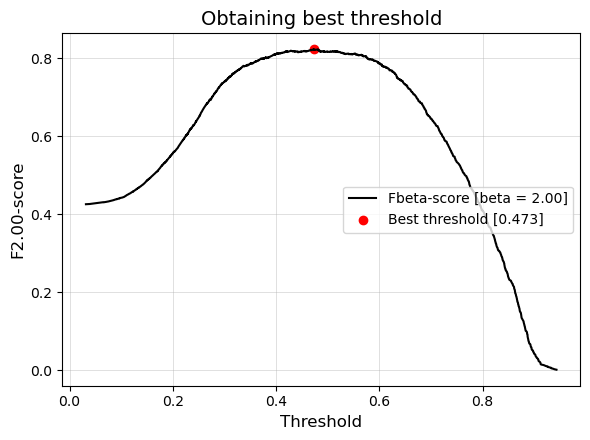

RF optimal threshold: 0.4727
RF best Fbeta-score: 0.8234


In [57]:
y_probs_RF_train = rf_model.predict_proba(X_train)
y_probs_RF_valid = rf_model.predict_proba(X_valid)
y_probs_RF_test = rf_model.predict_proba(X_test)

# Obtaining best threshold for Random Forest based on recall
rf_best_threshold, rf_best_score, rf_beta = hf.find_optimal_threshold(
    y_true=y_valid,
	y_proba=y_probs_RF_valid[:, 1],
    beta=beta
)
print(f'RF optimal threshold: {rf_best_threshold:.4f}')
print(f'RF best Fbeta-score: {rf_best_score:.4f}')

y_pred_RF_train = np.where(y_probs_RF_train[:, 1] > rf_best_threshold, 1, 0) # rf_model.predict(X_train)
y_pred_RF_valid = np.where(y_probs_RF_valid[:, 1] > rf_best_threshold, 1, 0) # rf_model.predict(X_valid)
y_pred_RF_test = np.where(y_probs_RF_test[:, 1] > rf_best_threshold, 1, 0) # rf_model.predict(X_test)

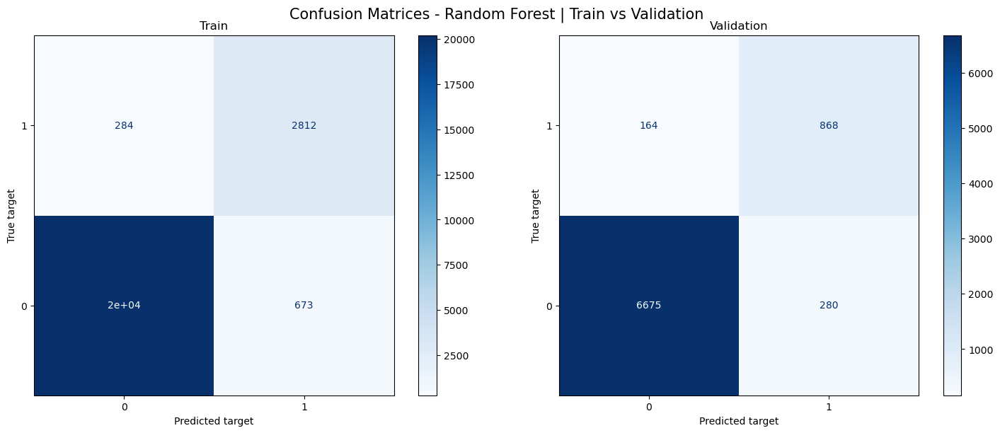

Train data:
Accuracy: 0.960
                  0        1  accuracy  macro avg  weighted avg
precision     0.986    0.807     0.960      0.897         0.963
recall        0.968    0.908     0.960      0.938         0.960
f1-score      0.977    0.855     0.960      0.916         0.961
support   20865.000 3096.000     0.960  23961.000     23961.000


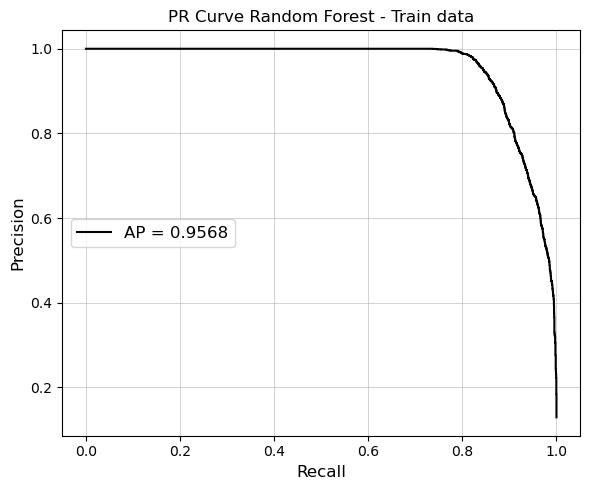


Validation data:
Accuracy: 0.944
                 0        1  accuracy  macro avg  weighted avg
precision    0.976    0.756     0.944      0.866         0.948
recall       0.960    0.841     0.944      0.900         0.944
f1-score     0.968    0.796     0.944      0.882         0.946
support   6955.000 1032.000     0.944   7987.000      7987.000


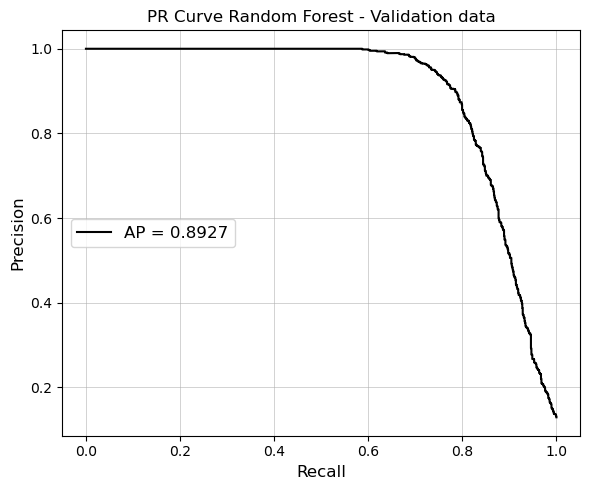

,0,1,accuracy,macro avg,weighted avg
precision,0.98,0.76,0.94,0.87,0.95
recall,0.96,0.84,0.94,0.90,0.94
f1-score,0.97,0.80,0.94,0.88,0.95
support,6955.00,1032.00,0.94,7987.00,7987.00


In [58]:
cm_train_RF, cm_test_RF = hf.display_confusion_matrix(
	y1_true=y_train,
	y1_pred=y_pred_RF_train,
	y2_true=y_valid,
	y2_pred=y_pred_RF_valid,
	title='Confusion Matrices - Random Forest | Train vs Validation',
	cmap="Blues",
	compare=['Train', 'Validation']
)
hf.quality_metrics(
	y_true=y_train,
	y_pred=y_pred_RF_train,
	y_probs=y_probs_RF_train[:, 1],
	label='Train data',
	pr_curve_title='PR Curve Random Forest - Train data'
)
hf.quality_metrics(
	y_true=y_valid,
	y_pred=y_pred_RF_valid,
	y_probs=y_probs_RF_valid[:, 1],
	label='\nValidation data',
	pr_curve_title='PR Curve Random Forest - Validation data'
)

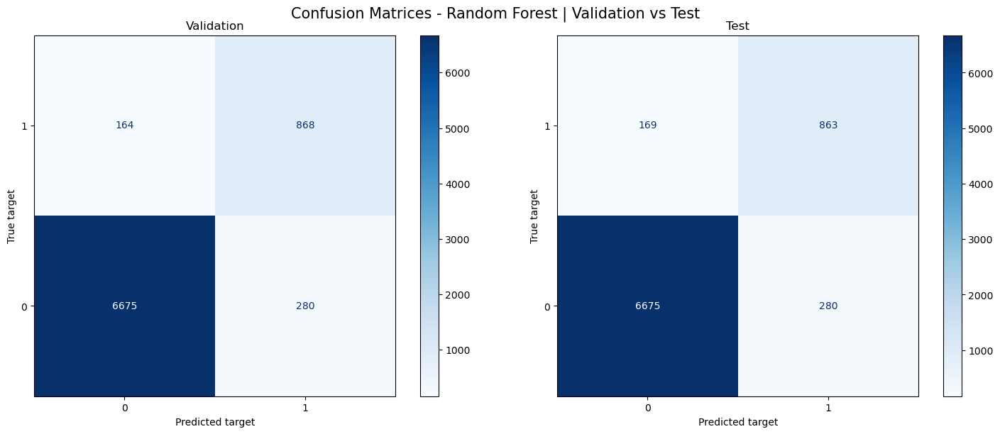

Validation data:
Accuracy: 0.944
                 0        1  accuracy  macro avg  weighted avg
precision    0.976    0.756     0.944      0.866         0.948
recall       0.960    0.841     0.944      0.900         0.944
f1-score     0.968    0.796     0.944      0.882         0.946
support   6955.000 1032.000     0.944   7987.000      7987.000


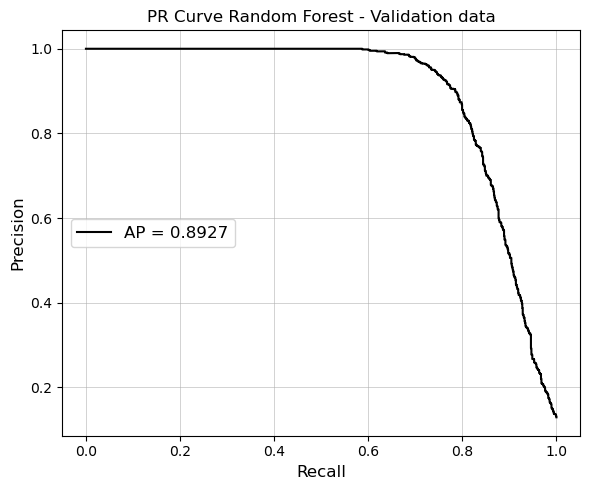


Test data:
Accuracy: 0.944
                 0        1  accuracy  macro avg  weighted avg
precision    0.975    0.755     0.944      0.865         0.947
recall       0.960    0.836     0.944      0.898         0.944
f1-score     0.967    0.794     0.944      0.881         0.945
support   6955.000 1032.000     0.944   7987.000      7987.000


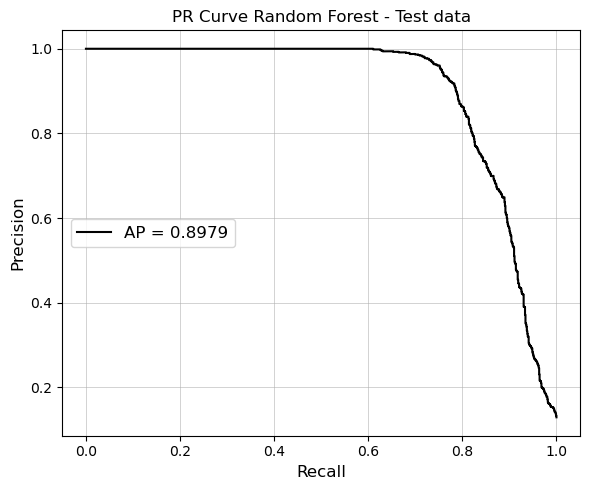

In [59]:
cm_train_RF, cm_test_RF = hf.display_confusion_matrix(
    y1_true=y_valid,
	y1_pred=y_pred_RF_valid,
	y2_true=y_test,
	y2_pred=y_pred_RF_test,
	title='Confusion Matrices - Random Forest | Validation vs Test',
	cmap="Blues",
	compare=['Validation', 'Test']
)
hf.quality_metrics(
    y_true=y_valid,
	y_pred=y_pred_RF_valid,
	y_probs=y_probs_RF_valid[:, 1],
	label='Validation data',
	pr_curve_title='PR Curve Random Forest - Validation data'
)
clf_report_rf_test = hf.quality_metrics(
    y_true=y_test,
	y_pred=y_pred_RF_test,
	y_probs=y_probs_RF_test[:, 1],
	label='\nTest data',
	pr_curve_title='PR Curve Random Forest - Test data'
)

#### Visualizing decision trees, feature importances and SHAP values for Random Forest model

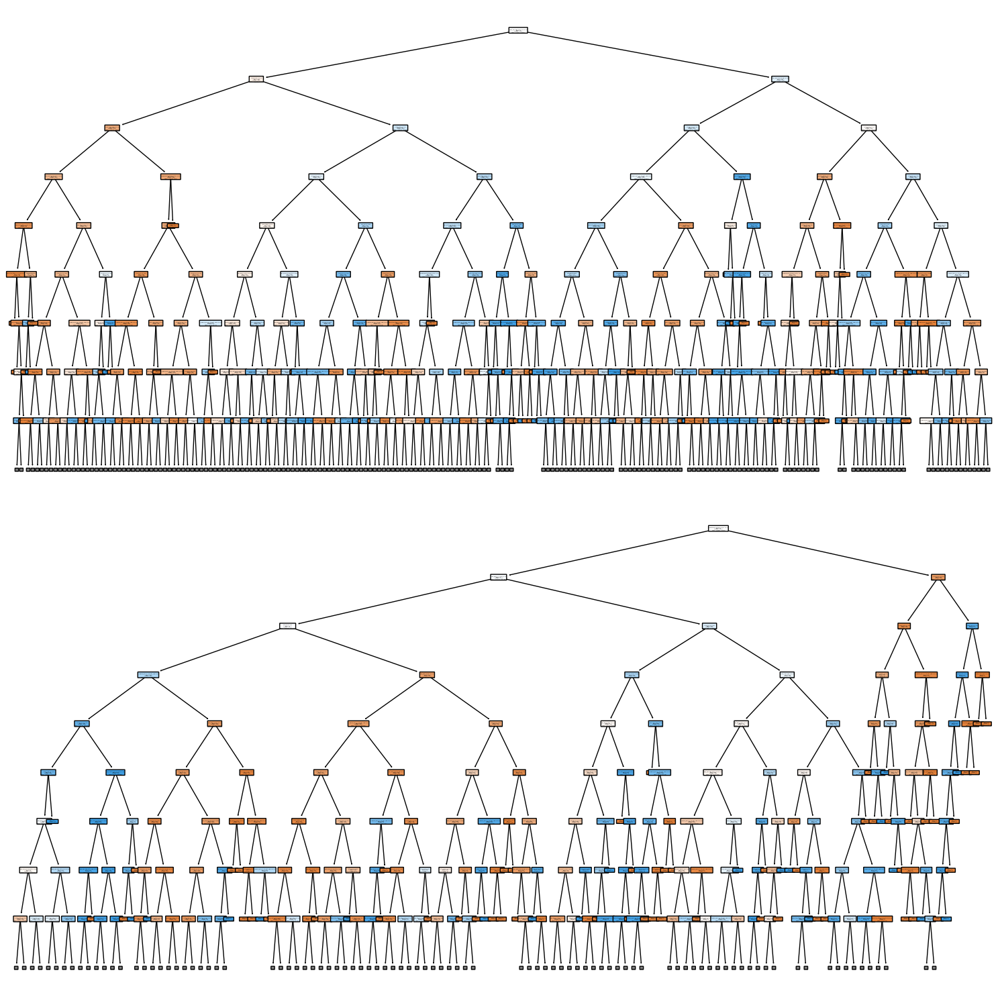

In [60]:
from sklearn import tree

"""Plots decision trees for Random Forest model for chosen tree indices (first and last tree)"""
estimators_to_plot = [0, -1] # first and last trees in the forest
fig, axes = plt.subplots(len(estimators_to_plot), 1, figsize=(15, 15))
axes = axes.flatten()
max_depth = 8
for tree_i, ax in zip(estimators_to_plot, axes):
    tree.plot_tree(
        decision_tree=rf_model.estimators_[tree_i],
        feature_names=rf_model.feature_names_in_,
        class_names=rf_model.classes_.astype(str),
     	filled=True,
        rounded=True,
        ax=ax,
        max_depth=max_depth
    )
plt.tight_layout()
plt.show()

Calculating feature importances for Random forest model ...


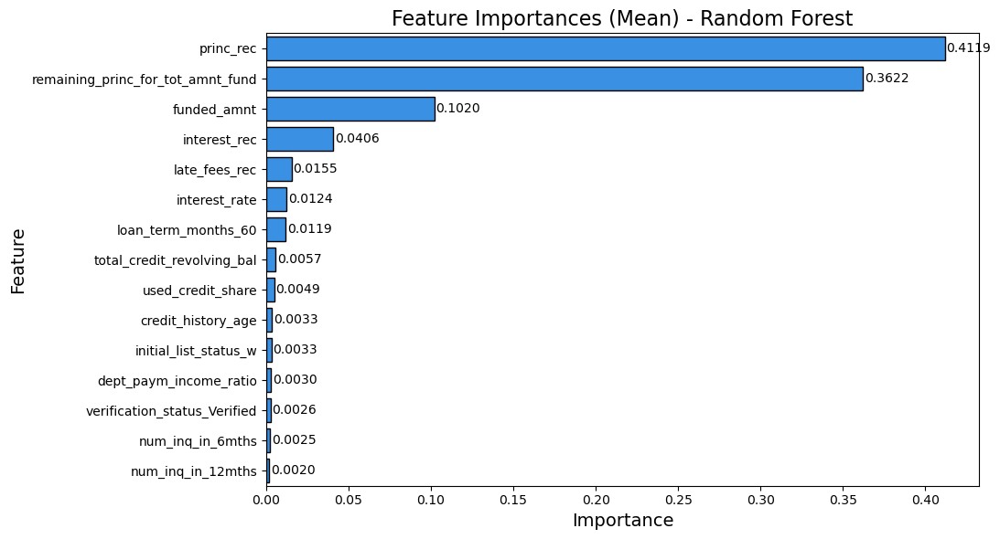

In [61]:
"""Feature importances for Random Forest model"""
rf_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
	threshold=rf_best_threshold,
	beta=rf_beta
)
rf_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
	model=rf_model,
	model_name='Random Forest',
	X_data=X_valid,
	y_data=y_valid,
	n_reps=5,
    scoring=rf_scorer,
	max_num_features=15,
	n_jobs=1
)

Calculating SHAP values for Random forest model ...
(.values =
array([[[ 7.18080941e-03, -7.18080941e-03],
        [-1.84447895e-02,  1.84447895e-02],
        [ 5.20040267e-03, -5.20040267e-03],
        ...,
        [ 2.41372800e-04, -2.41372800e-04],
        [ 2.23262777e-04, -2.23262777e-04],
        [ 4.75357168e-03, -4.75357168e-03]],

       [[ 1.07124488e-01, -1.07124488e-01],
        [-5.23840403e-02,  5.23840403e-02],
        [ 2.44966544e-02, -2.44966544e-02],
        ...,
        [-2.05414681e-04,  2.05414681e-04],
        [ 1.61178279e-04, -1.61178279e-04],
        [ 1.61505660e-03, -1.61505660e-03]],

       [[ 3.96654023e-02, -3.96654023e-02],
        [ 1.84429350e-02, -1.84429350e-02],
        [-9.84191297e-03,  9.84191297e-03],
        ...,
        [-9.29552837e-04,  9.29552837e-04],
        [ 2.46415424e-04, -2.46415424e-04],
        [ 1.63061025e-04, -1.63061025e-04]],

       ...,

       [[ 7.78464354e-02, -7.78464354e-02],
        [-6.07438734e-02,  6.07438734e-02],

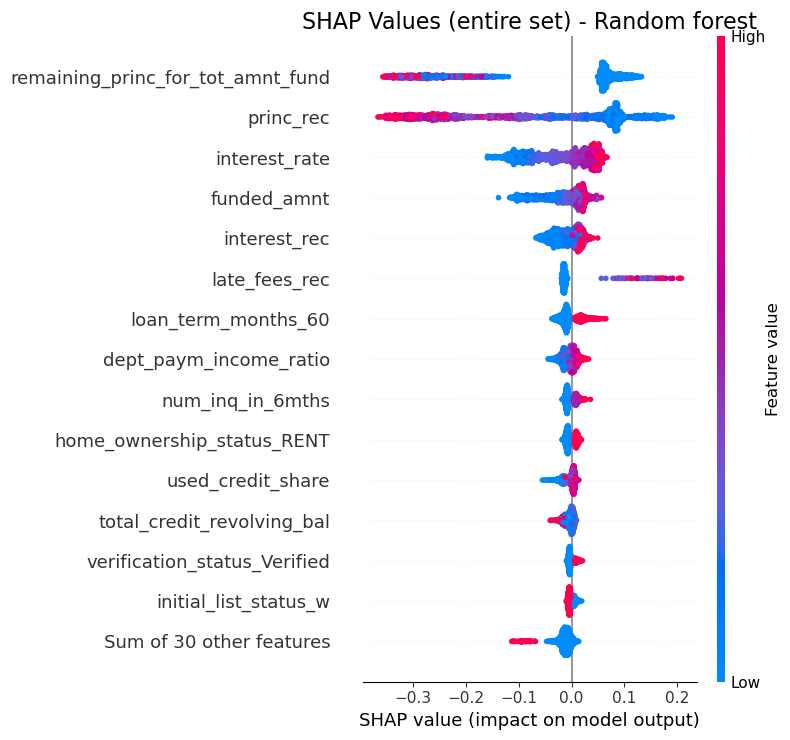

Sample pred: 1


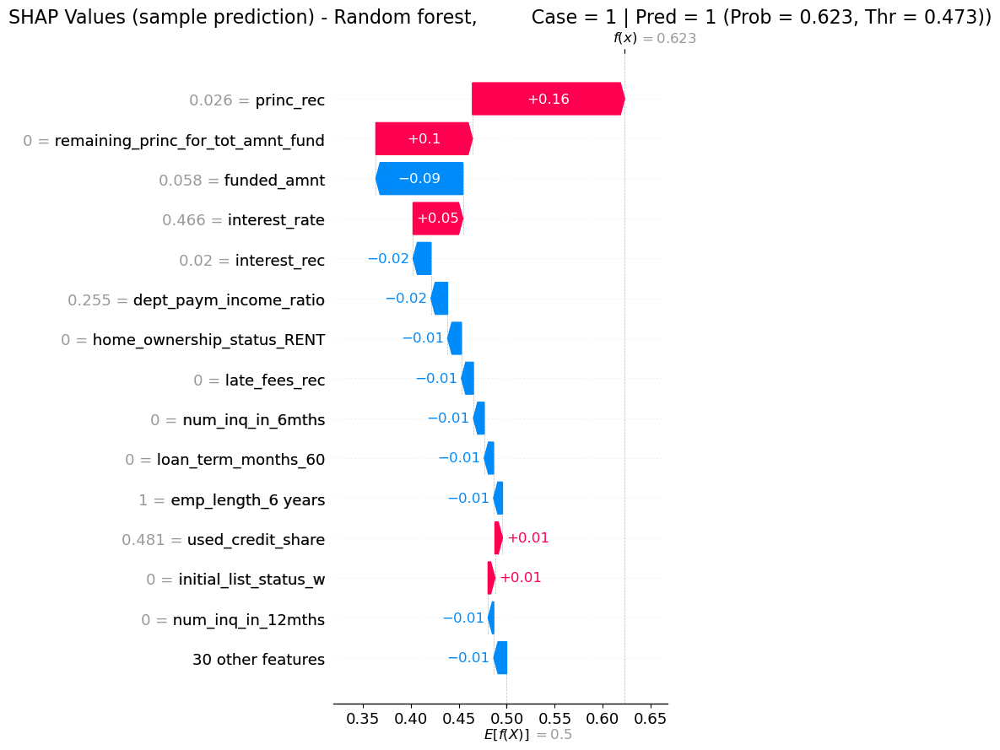

In [ ]:
hf.plot_shap_values(
    model=rf_model,
    model_name='Random Forest',
    X_train=X_train,
    y_train=y_train,
    X_valid=X_test,
    y_valid=y_test,
    threshold=rf_best_threshold,
    random_state=random_state
)

#### PCA Visualization - Random Forest

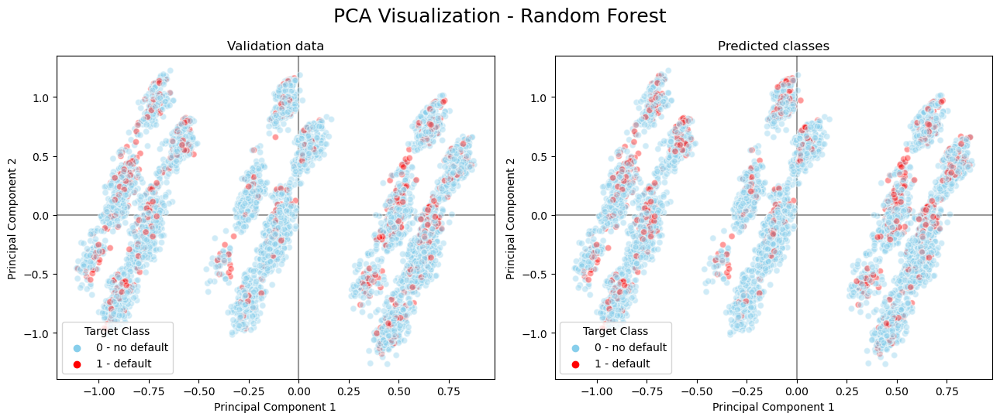

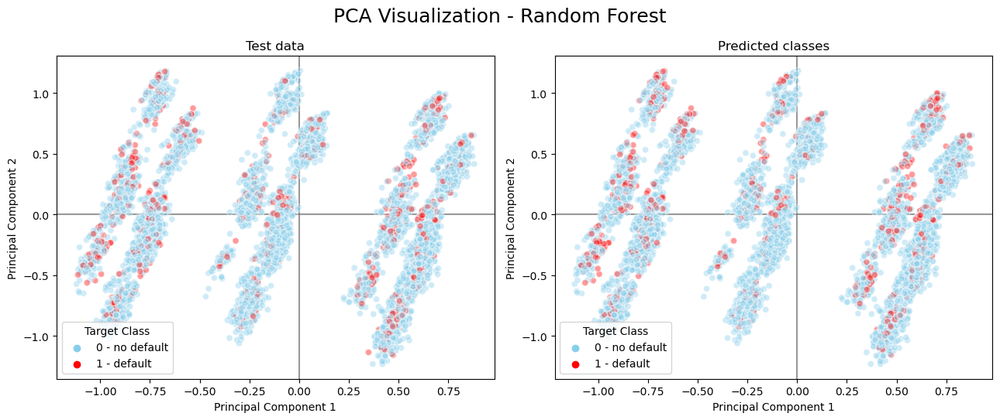

In [63]:
hf.pca_visualization(
	X_train=X_train,
    X_new=X_valid,
	y_new_true=y_valid,
	y_new_pred=y_pred_RF_valid,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Random Forest',
	valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
    X_train=X_train,	
	X_new=X_test,
	y_new_true=y_test,
	y_new_pred=y_pred_RF_test,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Random Forest',
	valid_or_test='Test',
	alpha=0.4
)

Random Forest training time: 1.27 seconds


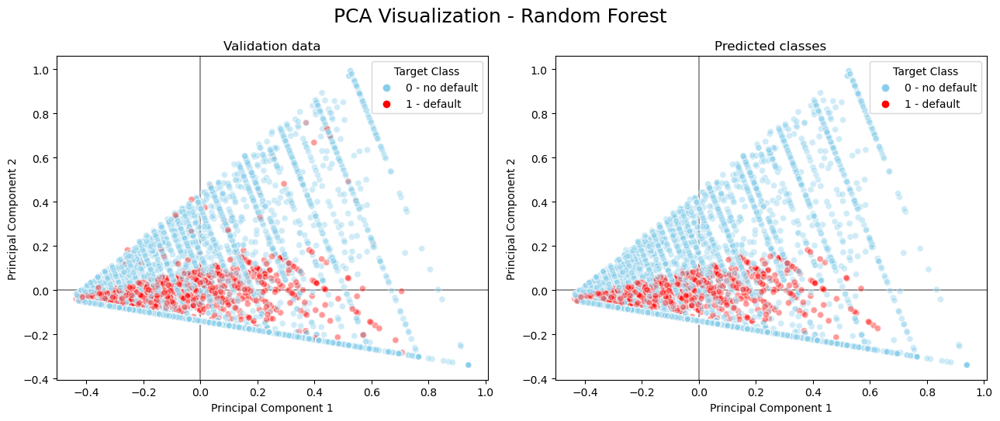

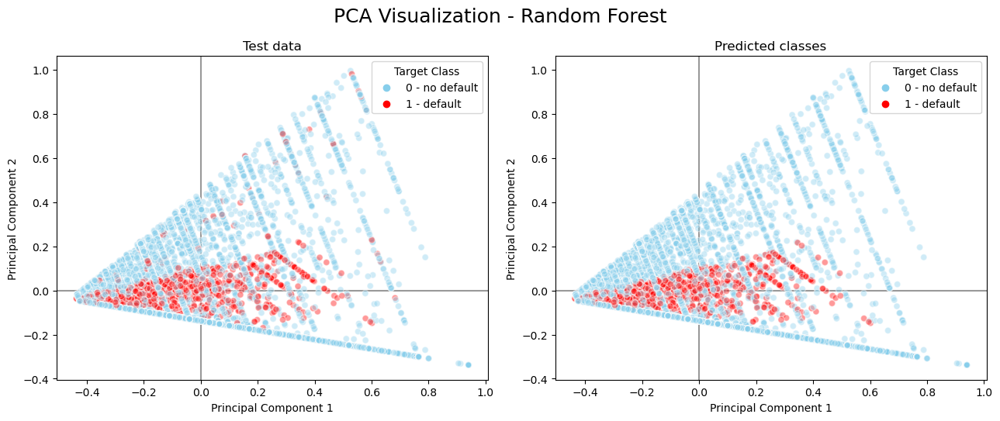

In [64]:
"""PCA for most important features based on feature importance plot"""
rf_most_important_feats = rf_feat_names_sorted_desc_by_importance[:3]
X_RF_train_important_feats = X_train[ rf_most_important_feats ]
X_RF_valid_important_feats = X_valid[ rf_most_important_feats ]
X_RF_test_important_feats = X_test[ rf_most_important_feats ]

"""Building Random Forest model using only most important features only for PCA visualization purposes"""
start_time = time.time()
rf_model_important_feats = RandomForestClassifier( **rf_model.get_params() )
rf_model_important_feats.fit(
    X=X_RF_train_important_feats,
    y=y_train
)

end_time = time.time()
print(f"Random Forest training time: {(end_time - start_time):.2f} seconds")

y_pred_RF_valid_imp_feats = rf_model_important_feats.predict( X_RF_valid_important_feats )
y_pred_RF_test_imp_feats = rf_model_important_feats.predict( X_RF_test_important_feats )

hf.pca_visualization(
    X_train=X_RF_train_important_feats,
    X_new=X_RF_valid_important_feats,
    y_new_true=y_valid,
    y_new_pred=y_pred_RF_valid_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Random Forest',
    valid_or_test='Validation',
    alpha=0.4
)
hf.pca_visualization(
    X_train=X_RF_train_important_feats,
    X_new=X_RF_test_important_feats,
    y_new_true=y_test,
    y_new_pred=y_pred_RF_test_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Random Forest',
    valid_or_test='Test',
    alpha=0.4
)

### Neural Network

Training Neural Network model and validation on validation data

In [65]:
from nn_for_classification import NeuralNetClassifier
from sklearn.utils.class_weight import compute_class_weight

# Computing class weights to handle class imbalance in the target variable for Neural Network model
class_weights = compute_class_weight(
	class_weight='balanced',
	classes=np.unique(y_train),
	y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

epochs = 2000
patience = 100

start_time = time.time()
nn_model = NeuralNetClassifier(
	hidden_layers_sizes=[64, 64, 32],
	dropout_prob=0.25,
	class_weights=class_weights,
	learning_rate=0.001,
	validation_split=0.25,
	epochs=epochs,
	regularization_type="L2",
	lambda_reg=0.001,
	patience=patience,
	random_state=random_state,
	device=device
)
# Neural Network model is trained on the whole training set (train + valid) with validation split inside the fit method for early stopping purposes
nn_model.fit(
	X=X_train_valid,
	y=y_train_valid
)
end_time = time.time()
print(f"\nNeural Network training time: {(end_time - start_time):.2f} seconds")

Epoch: 100 | Train loss: 0.23927 | Valid loss: 0.21404
Epoch: 200 | Train loss: 0.10929 | Valid loss: 0.13177
Epoch: 300 | Train loss: 0.08283 | Valid loss: 0.13877
Early stopping at epoch 312 ...

Epoch: 312 | Train loss: 0.08003 | Valid loss: 0.14420
Best model obtained at epoch 212
Epoch: 212 | Train loss: 0.10625 | Valid loss: 0.13018

Neural Network training time: 7.01 seconds


#### Training process visualisation

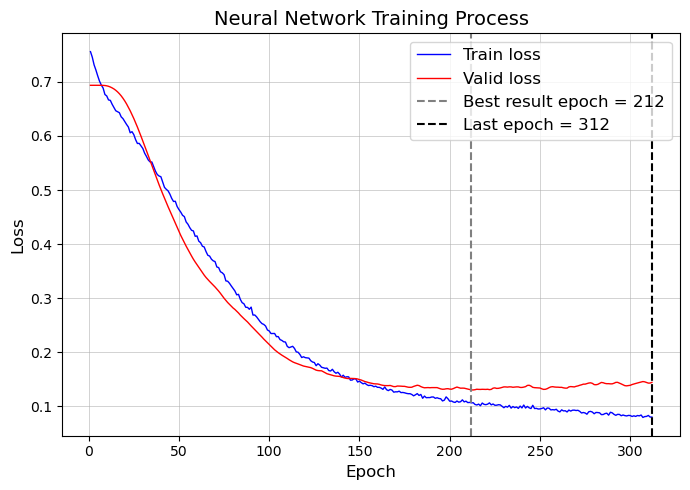

In [66]:
history = nn_model.history
epochs_axis = range(1, history.break_epoch + 1)
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_axis,
    history.train_losses,
    color='blue',
    linewidth=1,
    label='Train loss'
)
plt.plot(
    epochs_axis,
    history.valid_losses,
    color='red',
    linewidth=1,
    label='Valid loss'
)
plt.axvline(
    x=history.best_epoch,
    color='grey',
    linewidth=1.5,
    linestyle='--',
    label=f'Best result epoch = {history.best_epoch}'
)
plt.axvline(
    x=history.break_epoch,
    color='black',
    linewidth=1.5,
    linestyle='--',
    label=f'Last epoch = {history.break_epoch}'
)
plt.title('Neural Network Training Process', fontsize=14)
plt.legend(fontsize=12, loc='upper right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.grid(linewidth=0.4)
plt.tight_layout()
plt.show()

beta = 2, optimal_idx = 7025


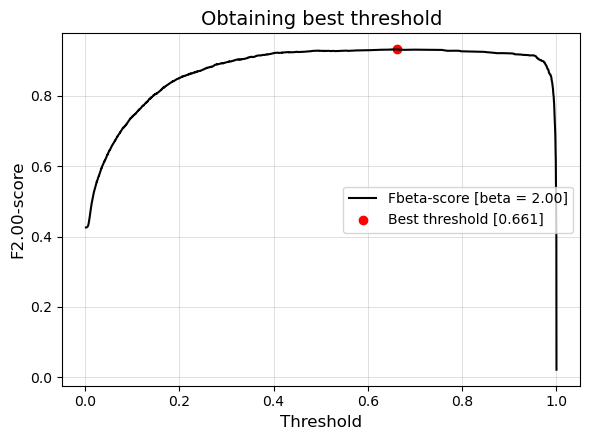

NN optimal threshold: 0.6615
NN best Fbeta-score: 0.9320


In [67]:
# Probabilities
y_probs_NN_train = nn_model.predict_proba(X_train)
y_probs_NN_valid = nn_model.predict_proba(X_valid)

# Obtaining best threshold for Neural Network based on Fbeta-score
nn_best_threshold, nn_best_score, nn_beta = hf.find_optimal_threshold(
	y_true=y_valid,
	y_proba=y_probs_NN_valid[:, 1],
    beta=beta
)
print(f'NN optimal threshold: {nn_best_threshold:.4f}')
print(f'NN best Fbeta-score: {nn_best_score:.4f}')

# Predictions (labels)
y_pred_NN_train = np.where(y_probs_NN_train[:, 1] > nn_best_threshold, 1, 0) # nn_model.predict(X_train)
y_pred_NN_valid = np.where(y_probs_NN_valid[:, 1] > nn_best_threshold, 1, 0) # nn_model.predict(X_valid)

#### Testing model on test data

In [68]:
"""Evaluating best model on test data"""
best_model = nn_model.history.best_model
print(best_model.layer_stack)

"""predict_proba() and predict() methods use best model"""
y_probs_NN_test = nn_model.predict_proba(X_test)
y_pred_NN_test = np.where(y_probs_NN_test[:, 1] > nn_best_threshold, 1, 0) # nn_model.predict(X_test)

# Loss on test data
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)
y_test_logits = best_model(X_test_tensor).squeeze() # forward step to get logits for test data
test_loss = history.loss_fn(y_test_logits, y_test_tensor).item()
print(f"Test loss: {test_loss:.5f}")

Sequential(
  (0): Linear(in_features=44, out_features=64, bias=True)
  (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.25, inplace=False)
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.25, inplace=False)
  (8): Linear(in_features=64, out_features=32, bias=True)
  (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Dropout(p=0.25, inplace=False)
  (12): Linear(in_features=32, out_features=2, bias=True)
)
Test loss: 0.13129


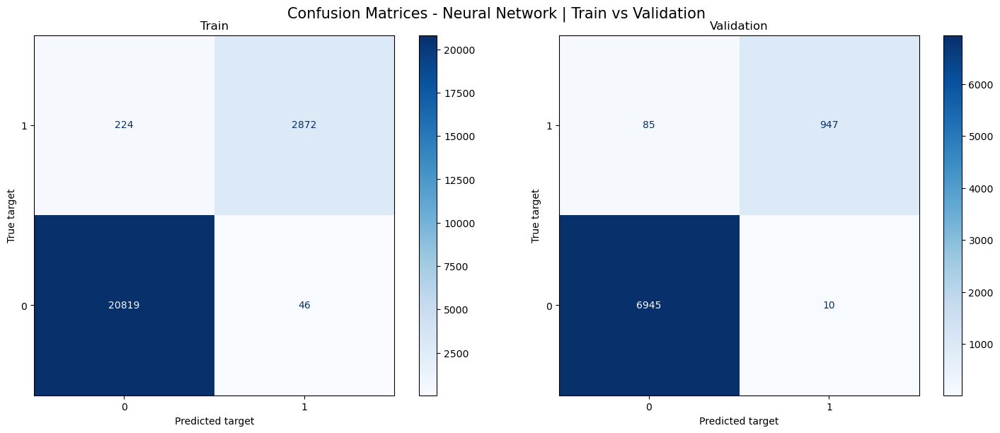

Train data:
Accuracy: 0.989
                  0        1  accuracy  macro avg  weighted avg
precision     0.989    0.984     0.989      0.987         0.989
recall        0.998    0.928     0.989      0.963         0.989
f1-score      0.994    0.955     0.989      0.974         0.989
support   20865.000 3096.000     0.989  23961.000     23961.000


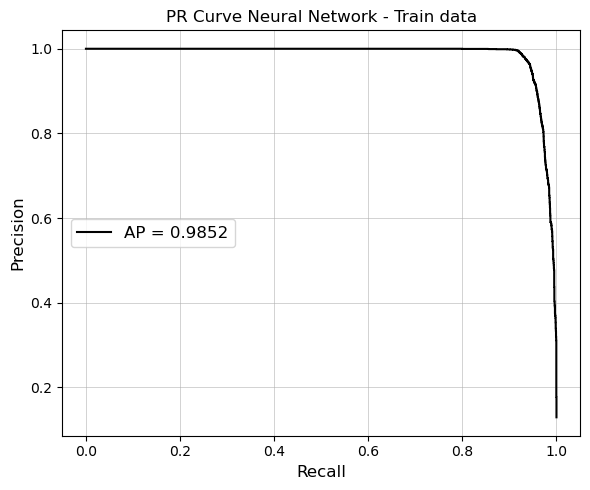


Validation data:
Accuracy: 0.988
                 0        1  accuracy  macro avg  weighted avg
precision    0.988    0.990     0.988      0.989         0.988
recall       0.999    0.918     0.988      0.958         0.988
f1-score     0.993    0.952     0.988      0.973         0.988
support   6955.000 1032.000     0.988   7987.000      7987.000


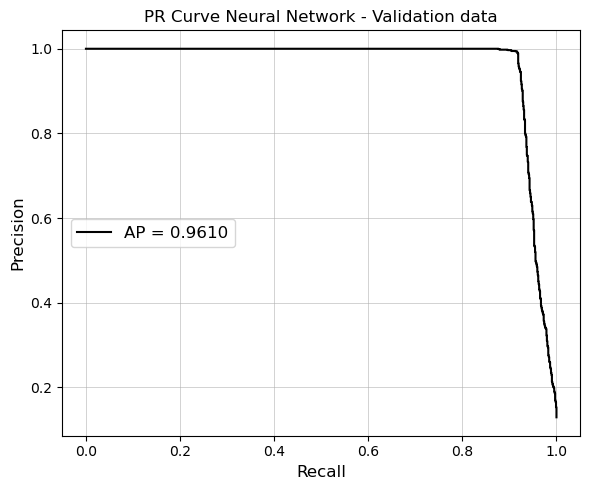

,0,1,accuracy,macro avg,weighted avg
precision,0.99,0.99,0.99,0.99,0.99
recall,1.00,0.92,0.99,0.96,0.99
f1-score,0.99,0.95,0.99,0.97,0.99
support,6955.00,1032.00,0.99,7987.00,7987.00


In [69]:
cm_train_NN, cm_valid_NN = hf.display_confusion_matrix(
    y1_true=y_train,
    y1_pred=y_pred_NN_train,
    y2_true=y_valid,
    y2_pred=y_pred_NN_valid,
    title='Confusion Matrices - Neural Network | Train vs Validation',
    cmap="Blues"
)
hf.quality_metrics(
    y_true=y_train,
    y_pred=y_pred_NN_train,
	y_probs=y_probs_NN_train[:, 1],
    label='Train data',
    pr_curve_title='PR Curve Neural Network - Train data'
)
hf.quality_metrics(
    y_true=y_valid,
    y_pred=y_pred_NN_valid,
    y_probs=y_probs_NN_valid[:, 1],
    label='\nValidation data',
    pr_curve_title='PR Curve Neural Network - Validation data'
)

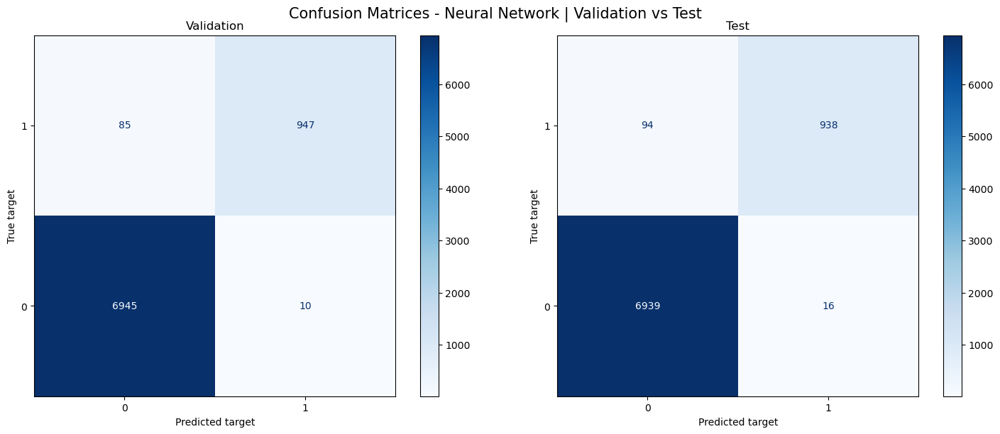

Validation data:
Accuracy: 0.988
                 0        1  accuracy  macro avg  weighted avg
precision    0.988    0.990     0.988      0.989         0.988
recall       0.999    0.918     0.988      0.958         0.988
f1-score     0.993    0.952     0.988      0.973         0.988
support   6955.000 1032.000     0.988   7987.000      7987.000


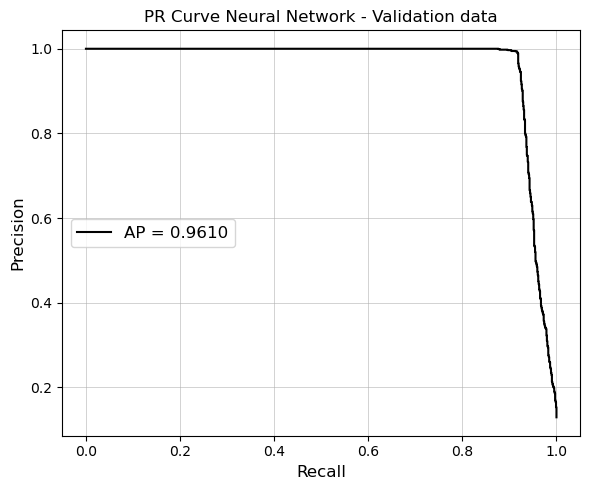


Test data:
Accuracy: 0.986
                 0        1  accuracy  macro avg  weighted avg
precision    0.987    0.983     0.986      0.985         0.986
recall       0.998    0.909     0.986      0.953         0.986
f1-score     0.992    0.945     0.986      0.968         0.986
support   6955.000 1032.000     0.986   7987.000      7987.000


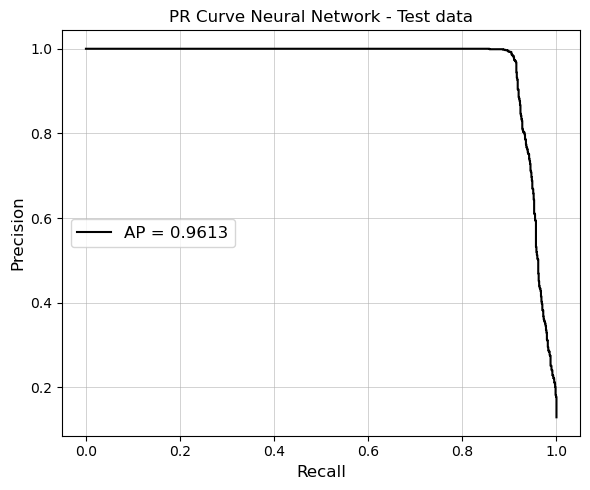

In [70]:
cm_valid_NN, cm_test_NN = hf.display_confusion_matrix(
    y1_true=y_valid,
    y1_pred=y_pred_NN_valid,
    y2_true=y_test,
    y2_pred=y_pred_NN_test,
    title='Confusion Matrices - Neural Network | Validation vs Test',
    cmap="Blues",
    compare=['Validation', 'Test']
)
hf.quality_metrics(
    y_true=y_valid,
    y_pred=y_pred_NN_valid,
    y_probs=y_probs_NN_valid[:, 1],
    label='Validation data',
    pr_curve_title='PR Curve Neural Network - Validation data'
)
clf_report_nn_test = hf.quality_metrics(
    y_true=y_test,
    y_pred=y_pred_NN_test,
    y_probs=y_probs_NN_test[:, 1],
    label='\nTest data',
    pr_curve_title='PR Curve Neural Network - Test data'
)

#### Feature importances and SHAP values for Neural Network model

Calculating feature importances for Neural network model ...


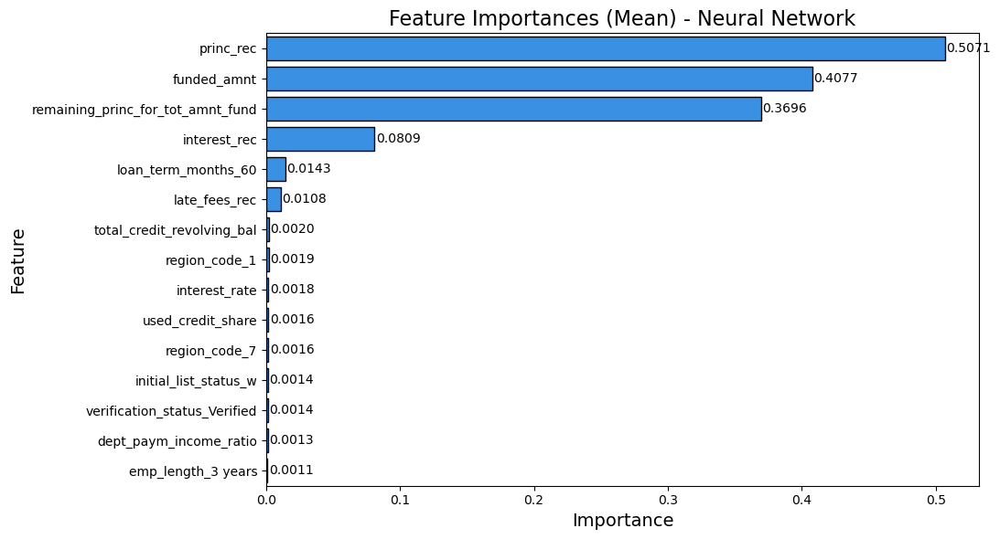

In [71]:
nn_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
	threshold=nn_best_threshold,
    beta=nn_beta
)
nn_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
	model=nn_model,
	model_name='Neural Network',
	X_data=X_valid,
	y_data=y_valid,
	n_reps=5,
    scoring=nn_scorer,
	max_num_features=15,
	n_jobs=2
)

Calculating SHAP values for Neural network model ...


PermutationExplainer explainer: 7988it [03:42, 35.50it/s]                          


(.values =
array([[[ 1.12465020e-01, -1.12465021e-01],
        [-2.82057043e-02,  2.82057015e-02],
        [-6.81613510e-03,  6.81612823e-03],
        ...,
        [ 5.41596144e-03, -5.41596234e-03],
        [ 1.06429787e-03, -1.06429855e-03],
        [-2.23575631e-02,  2.23575594e-02]],

       [[-1.59279125e-01,  1.59279124e-01],
        [ 5.69180709e-04, -5.69171989e-04],
        [-1.23193359e-04,  1.23195675e-04],
        ...,
        [ 2.23375690e-03, -2.23375759e-03],
        [ 8.91545703e-05, -8.91551414e-05],
        [-1.42796085e-02,  1.42796101e-02]],

       [[-1.98534900e-01,  1.98534907e-01],
        [-9.94310378e-03,  9.94309922e-03],
        [-1.15044445e-03,  1.15043668e-03],
        ...,
        [ 1.11021284e-02, -1.11021286e-02],
        [ 1.67444281e-03, -1.67444379e-03],
        [ 6.71668759e-03, -6.71668806e-03]],

       ...,

       [[ 1.85540407e-02, -1.85540320e-02],
        [-1.29366691e-03,  1.29366291e-03],
        [-2.58339729e-04,  2.58339925e-04],
       

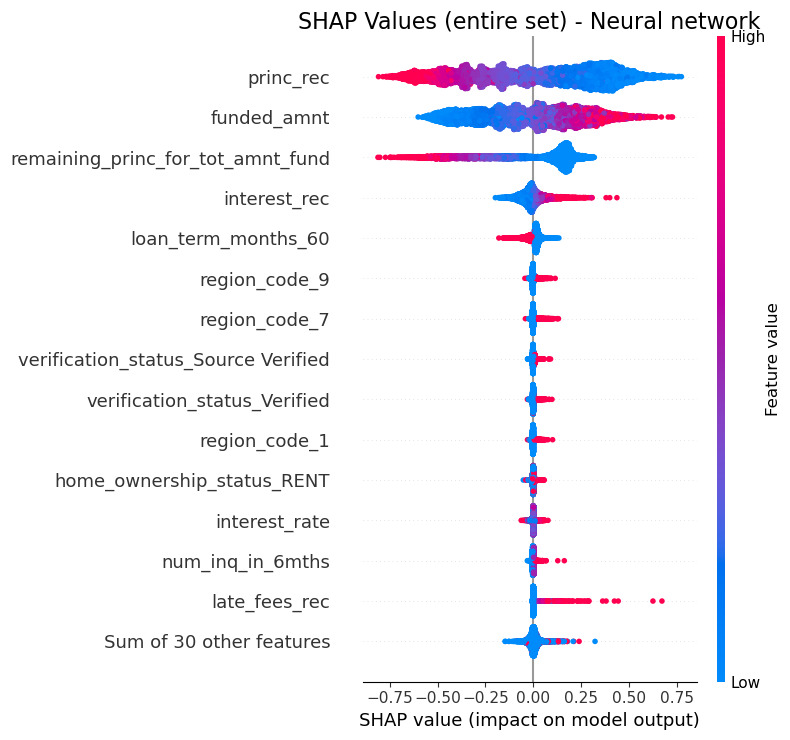

Sample pred: 1


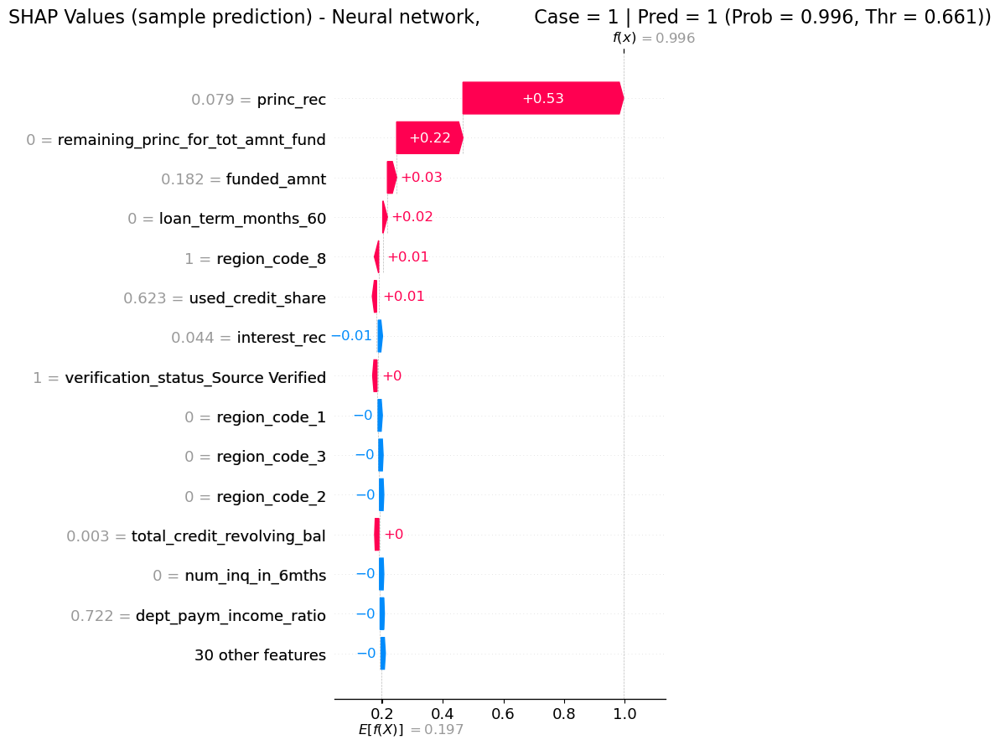

In [ ]:
hf.plot_shap_values(
    model=nn_model,
    model_name="Neural Network",
    X_train=X_train,
    y_train=y_train,
	X_valid=X_test,
    y_valid=y_test,
    threshold=nn_best_threshold,
    random_state=random_state
)

#### PCA Visualization - Neural Network

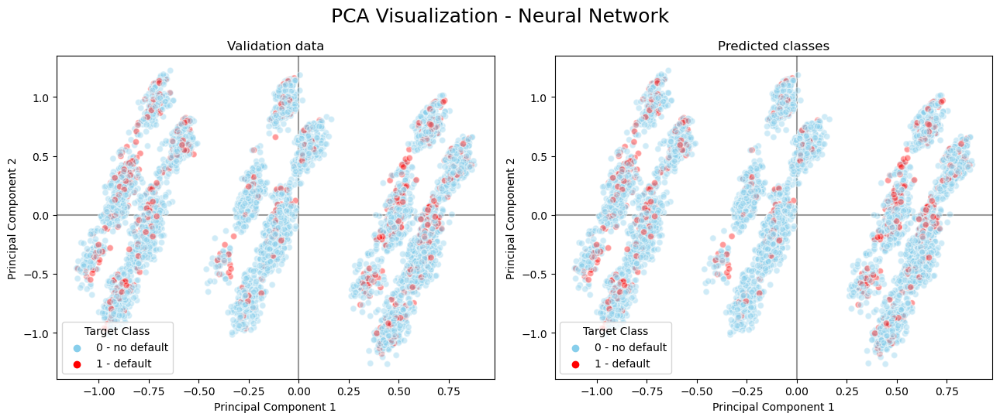

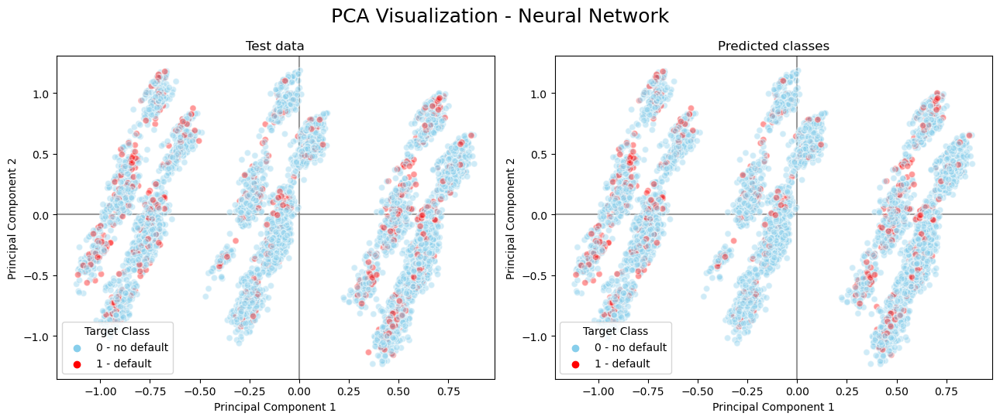

In [73]:
hf.pca_visualization(
	X_train=X_train,
    X_new=X_valid,
	y_new_true=y_valid,
	y_new_pred=y_pred_NN_valid,
    colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Neural Network',
	valid_or_test='Validation',
	alpha=0.4
)
hf.pca_visualization(
    X_train=X_train,
    X_new=X_test,
    y_new_true=y_test,
    y_new_pred=y_pred_NN_test,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Neural Network',
    valid_or_test='Test',
    alpha=0.4
)

Epoch: 100 | Train loss: 0.17249 | Valid loss: 0.16443
Epoch: 200 | Train loss: 0.13805 | Valid loss: 0.13593
Epoch: 300 | Train loss: 0.12736 | Valid loss: 0.12984
Epoch: 400 | Train loss: 0.12215 | Valid loss: 0.12237
Epoch: 500 | Train loss: 0.11838 | Valid loss: 0.11998
Epoch: 600 | Train loss: 0.11569 | Valid loss: 0.11367
Epoch: 700 | Train loss: 0.11576 | Valid loss: 0.11117
Epoch: 800 | Train loss: 0.11336 | Valid loss: 0.11100
Epoch: 900 | Train loss: 0.11256 | Valid loss: 0.11120
Epoch: 1000 | Train loss: 0.11173 | Valid loss: 0.11147
Early stopping at epoch 1047 ...

Epoch: 1047 | Train loss: 0.11079 | Valid loss: 0.11031
Best model obtained at epoch 947
Epoch: 947 | Train loss: 0.11242 | Valid loss: 0.10848

Neural Network training time: 7.55 seconds


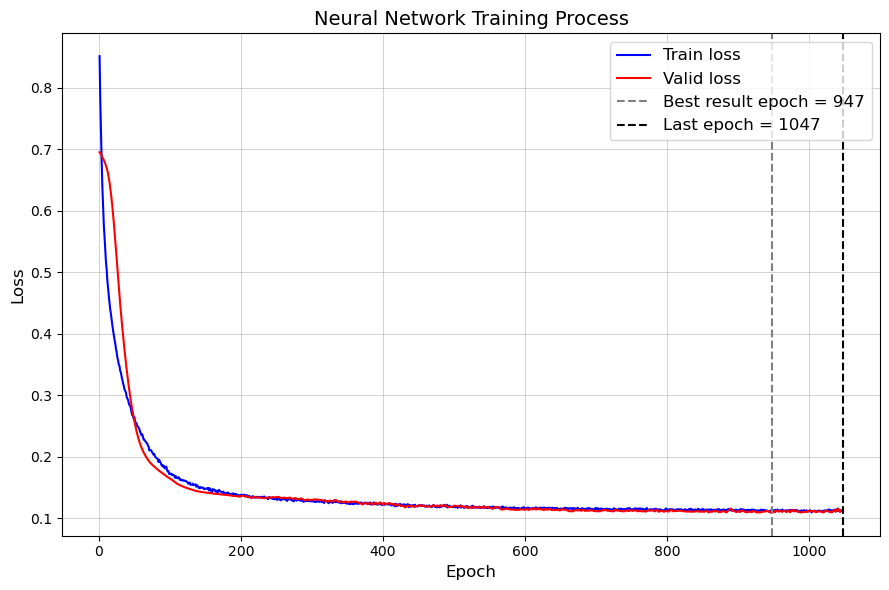

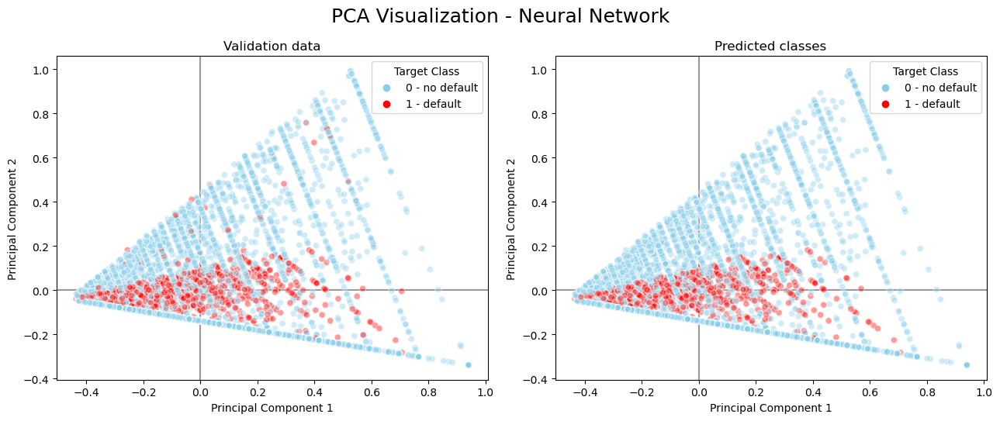

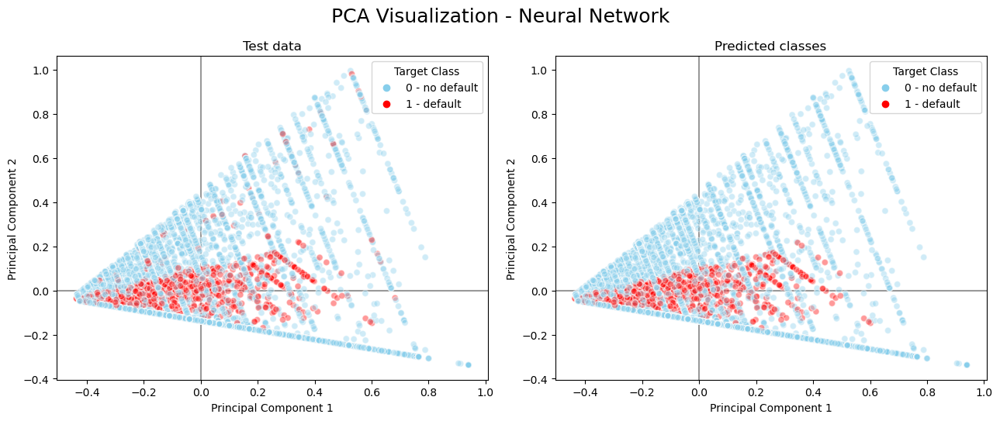

In [74]:
"""PCA for most important features based on feature importance plot"""
nn_most_important_feats = nn_feat_names_sorted_desc_by_importance[:3]
X_NN_train_valid_important_feats = X_train_valid[ nn_most_important_feats ]
X_NN_train_important_feats = X_train[ nn_most_important_feats ]
X_NN_valid_important_feats = X_valid[ nn_most_important_feats ]
X_NN_test_important_feats = X_test[ nn_most_important_feats ]

"""Building Neural Network model using only most important features only for PCA visualization purposes"""
start_time = time.time()
nn_model_important_feats = NeuralNetClassifier( **nn_model.get_params() )
nn_model_important_feats.fit(
    X=X_NN_train_valid_important_feats,
    y=y_train_valid
)
end_time = time.time()
print(f"\nNeural Network training time: {(end_time - start_time):.2f} seconds")

y_pred_NN_valid_imp_feats = nn_model_important_feats.predict( X_NN_valid_important_feats )
y_pred_NN_test_imp_feats = nn_model_important_feats.predict( X_NN_test_important_feats )

nn_imp_feats_history = nn_model_important_feats.history
epochs_axis = range(1, nn_imp_feats_history.break_epoch + 1)
plt.figure(figsize=(9, 6))
plt.plot(
    epochs_axis,
    nn_imp_feats_history.train_losses,
    color='blue',
    linewidth=1.5,
    label='Train loss'
)
plt.plot(
    epochs_axis,
    nn_imp_feats_history.valid_losses,
    color='red',
    linewidth=1.5,
    label='Valid loss'
)
plt.axvline(
    x=nn_imp_feats_history.best_epoch,
    color='gray',
    linewidth=1.5,
    linestyle='--',
    label=f'Best result epoch = {nn_imp_feats_history.best_epoch}'
)
plt.axvline(
    x=nn_imp_feats_history.break_epoch,
    color='black',
    linewidth=1.5,
    linestyle='--',
    label=f'Last epoch = {nn_imp_feats_history.break_epoch}'
)
plt.title('Neural Network Training Process', fontsize=14)
plt.legend(fontsize=12, loc='upper right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.grid(linewidth=0.4)
plt.tight_layout()
plt.show()

hf.pca_visualization(
    X_train=X_NN_train_important_feats,
    X_new=X_NN_valid_important_feats,
    y_new_true=y_valid,
    y_new_pred=y_pred_NN_valid_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Neural Network',
    valid_or_test='Validation',
    alpha=0.4
)
hf.pca_visualization(
    X_train=X_NN_train_important_feats,
    X_new=X_NN_test_important_feats,
    y_new_true=y_test,
    y_new_pred=y_pred_NN_test_imp_feats,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Neural Network',
    valid_or_test='Test',
    alpha=0.4
)

### Visualising PR curves for each method for test data

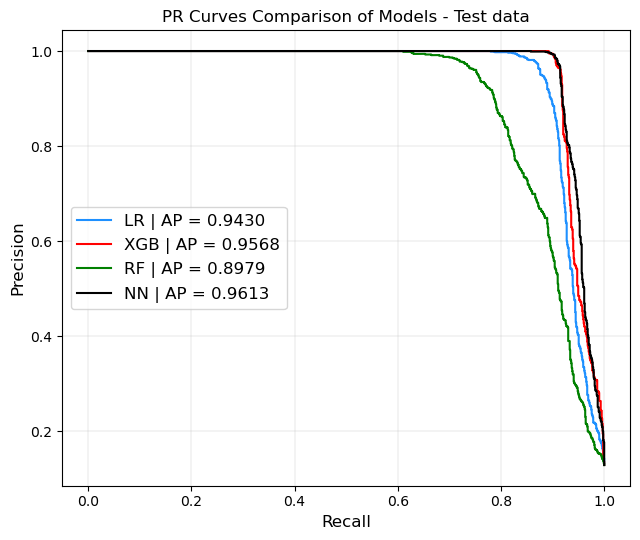

In [75]:
y_probs_test = [y_probs_LR_test, y_probs_XGB_test, y_probs_RF_test, y_probs_NN_test]
model_names = ['LR', 'XGB', 'RF', 'NN']
colors = ['dodgerblue', 'red', 'green', 'black']

plt.figure(figsize=(6.5, 5.5))
for probs, name, color in zip(y_probs_test, model_names, colors):
    precisions, recalls, _ = hf.precision_recall_curve(y_true=y_test, y_score=probs[:, 1], pos_label=1)
    avg_precision_score = hf.average_precision_score(y_true=y_test, y_score=probs[:, 1])
    plt.plot(
		recalls,
		precisions,
		label=f'{name} | AP = {avg_precision_score:.4f}',
		color=color
    )
plt.xlabel('Recall', fontsize=12); plt.ylabel('Precision', fontsize=12)
plt.legend(loc='center left', fontsize=12)
plt.title('PR Curves Comparison of Models - Test data', fontsize=12)
plt.grid(linewidth=0.2)
plt.tight_layout()
plt.show()

In [76]:
"""Fbeta-score for all models on test data with beta value calculated based on class imbalance in the target variable to give more weight to recall than precision"""
beta = np.sqrt(class_freq_ratio) # giving more weight to recall than precision due to class imbalance in the target variable
lr_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_LR_test, beta=beta)
xgb_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_XGB_test, beta=beta)
rf_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_RF_test, beta=beta)
nn_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_NN_test, beta=beta)

lr_recall = clf_report_lr_test.loc['recall', '1']
xgb_recall = clf_report_xgb_test.loc['recall', '1']
rf_recall = clf_report_rf_test.loc['recall', '1']
nn_recall = clf_report_nn_test.loc['recall', '1']

models_recalls = {
    "LR": [lr_fbeta_score, lr_recall],
    "XGB": [xgb_fbeta_score, xgb_recall],
    "RF": [rf_fbeta_score, rf_recall],
    "NN": [nn_fbeta_score, nn_recall]
}
fbeta_score_colname = f'F{beta.round(1)}-score'

In [77]:
old_format = pd.options.display.float_format
pd.options.display.float_format = '{:.3f}'.format

scores_df = pd.DataFrame(
    models_recalls.values(),
    index=models_recalls.keys(),
    columns=['Recall', fbeta_score_colname]
)
scores_df

,Recall,F2.6-score
LR,0.896,0.892
XGB,0.916,0.909
RF,0.825,0.836
NN,0.918,0.909


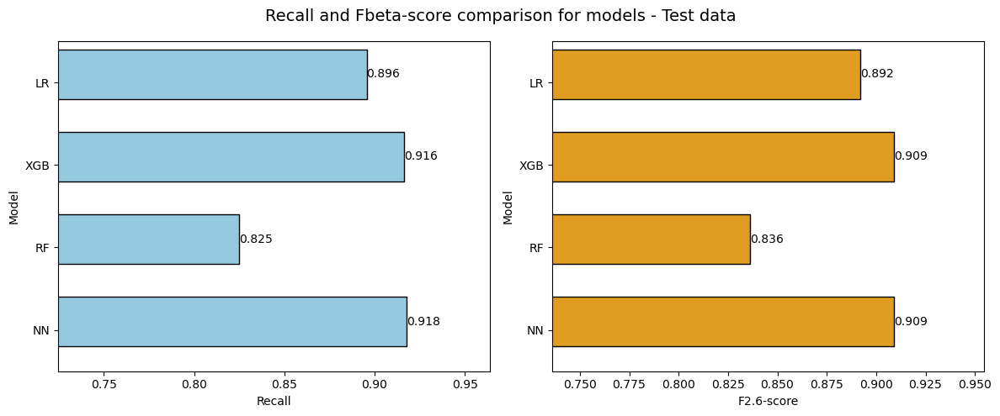

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(
    data=scores_df,
    x="Recall",
    y=scores_df.index,
    ax=axes[0],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='skyblue'
)
axes[0].bar_label(axes[0].containers[0], fmt='%.3f')
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Model")
axes[0].set_xlim( left=scores_df['Recall'].min() - 0.1 )

sns.barplot(
    data=scores_df,
    x=fbeta_score_colname,
    y=scores_df.index,
    ax=axes[1],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='orange'
)
axes[1].bar_label(axes[1].containers[0], fmt='%.3f')
axes[1].set_xlabel(fbeta_score_colname)
axes[1].set_ylabel("Model")
axes[1].set_xlim( left=scores_df[fbeta_score_colname].min() - 0.1 )
plt.suptitle('Recall and Fbeta-score comparison for models - Test data', fontsize=14)
plt.tight_layout()
plt.show()

In [79]:
pd.options.display.float_format = old_format
gloabl_end_time = time.time()
print(f"Total execution time: {(gloabl_end_time - global_start_time):.2f} seconds")

Total execution time: 641.60 seconds


In [83]:
from sklearn.model_selection import cross_val_score
lr_cross_val_scores = cross_val_score(
	estimator=log_reg_model,
	X=X_train_valid,
	y=y_train_valid,
    scoring=lr_scorer
)
print(f"Cross-validation scores for Logistic Regression model: {lr_cross_val_scores}, mean score: {lr_cross_val_scores.mean():.4f}, std: {lr_cross_val_scores.std():.4f}")
rf_cross_val_scores = cross_val_score(
	estimator=rf_model,
	X=X_train_valid,
	y=y_train_valid,
	scoring=rf_scorer,
	n_jobs=-1
)
print(f"Cross-validation scores for Random Forest model: {rf_cross_val_scores}, mean score: {rf_cross_val_scores.mean():.4f}, std: {rf_cross_val_scores.std():.4f}")
nn_cross_val_scores = cross_val_score(
	estimator=nn_model,
	X=X_train_valid,
	y=y_train_valid,
	scoring=nn_scorer,
	n_jobs=-1
)
print(f"Cross-validation scores for Neural Network model: {nn_cross_val_scores}, mean score: {nn_cross_val_scores.mean():.4f}, std: {nn_cross_val_scores.std():.4f}")

Cross-validation scores for Logistic Regression model: [0.90208078 0.9102001  0.90709583 0.88155627 0.91806876], mean score: 0.9038, std: 0.0123
Cross-validation scores for Random Forest model: [0.82741477 0.8377214  0.85272248 0.79165679 0.84210526], mean score: 0.8303, std: 0.0210
Cross-validation scores for Neural Network model: [0.92685371 0.92831962 0.92395343 0.9039269  0.92751843], mean score: 0.9221, std: 0.0092
